In [ ]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

In [1]:
import os
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt

print("TensorFlow:", tf.__version__)
print("GPU devices:", tf.config.list_physical_devices("GPU"))

# Enable GPU memory growth
gpus = tf.config.list_physical_devices("GPU")

for gpu in gpus:
    try:
        tf.config.experimental.set_memory_growth(gpu, True)
    except RuntimeError:
        pass

print("Number of GPUs:", len(gpus))

TensorFlow: 2.20.0
GPU devices: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]
Number of GPUs: 2


In [2]:
import os
import pandas as pd

DATA_DIR = "/kaggle/input/datasets/kmader/skin-cancer-mnist-ham10000"

PART1 = os.path.join(DATA_DIR, "HAM10000_images_part_1")
PART2 = os.path.join(DATA_DIR, "HAM10000_images_part_2")
METADATA_PATH = os.path.join(DATA_DIR, "HAM10000_metadata.csv")

print("Part 1 exists:", os.path.exists(PART1))
print("Part 2 exists:", os.path.exists(PART2))
print("Metadata exists:", os.path.exists(METADATA_PATH))

metadata = pd.read_csv(METADATA_PATH)

print("\nMetadata shape:", metadata.shape)
print("\nColumns:")
print(metadata.columns.tolist())

print("\nClass distribution:")
print(metadata["dx"].value_counts())

Part 1 exists: True
Part 2 exists: True
Metadata exists: True

Metadata shape: (10015, 7)

Columns:
['lesion_id', 'image_id', 'dx', 'dx_type', 'age', 'sex', 'localization']

Class distribution:
dx
nv       6705
mel      1113
bkl      1099
bcc       514
akiec     327
vasc      142
df        115
Name: count, dtype: int64


In [3]:
def find_image_path(image_id):
    path1 = os.path.join(PART1, image_id + ".jpg")
    path2 = os.path.join(PART2, image_id + ".jpg")

    if os.path.exists(path1):
        return path1
    elif os.path.exists(path2):
        return path2
    else:
        return None


metadata["image_path"] = metadata["image_id"].apply(find_image_path)

print("Total images:", len(metadata))
print("Images found:", metadata["image_path"].notna().sum())
print("Images missing:", metadata["image_path"].isna().sum())

print("\nExample paths:")
print(metadata[["image_id", "dx", "image_path"]].head())

Total images: 10015
Images found: 10015
Images missing: 0

Example paths:
       image_id   dx                                         image_path
0  ISIC_0027419  bkl  /kaggle/input/datasets/kmader/skin-cancer-mnis...
1  ISIC_0025030  bkl  /kaggle/input/datasets/kmader/skin-cancer-mnis...
2  ISIC_0026769  bkl  /kaggle/input/datasets/kmader/skin-cancer-mnis...
3  ISIC_0025661  bkl  /kaggle/input/datasets/kmader/skin-cancer-mnis...
4  ISIC_0031633  bkl  /kaggle/input/datasets/kmader/skin-cancer-mnis...


In [4]:
from sklearn.model_selection import train_test_split

# First: 80% temporary training data, 20% test data
train_val, test = train_test_split(
    metadata,
    test_size=0.20,
    random_state=42,
    stratify=metadata["dx"]
)

# Second: split the remaining 80% into
# approximately 70% training and 10% validation
train, val = train_test_split(
    train_val,
    test_size=0.125,
    random_state=42,
    stratify=train_val["dx"]
)

print("Train:", len(train))
print("Validation:", len(val))
print("Test:", len(test))

print("\nTrain distribution:")
print(train["dx"].value_counts())

print("\nValidation distribution:")
print(val["dx"].value_counts())

print("\nTest distribution:")
print(test["dx"].value_counts())

Train: 7010
Validation: 1002
Test: 2003

Train distribution:
dx
nv       4693
mel       779
bkl       769
bcc       360
akiec     229
vasc      100
df         80
Name: count, dtype: int64

Validation distribution:
dx
nv       671
mel      111
bkl      110
bcc       51
akiec     33
vasc      14
df        12
Name: count, dtype: int64

Test distribution:
dx
nv       1341
mel       223
bkl       220
bcc       103
akiec      65
vasc       28
df         23
Name: count, dtype: int64


In [5]:
from sklearn.preprocessing import LabelEncoder

label_encoder = LabelEncoder()

# Fit on all 7 diagnosis names
label_encoder.fit(metadata["dx"])

train_labels = label_encoder.transform(train["dx"])
val_labels = label_encoder.transform(val["dx"])
test_labels = label_encoder.transform(test["dx"])

print("Classes:")
print(label_encoder.classes_)

print("\nTrain labels:", train_labels.shape)
print("Validation labels:", val_labels.shape)
print("Test labels:", test_labels.shape)

Classes:
['akiec' 'bcc' 'bkl' 'df' 'mel' 'nv' 'vasc']

Train labels: (7010,)
Validation labels: (1002,)
Test labels: (2003,)


In [6]:
train_paths = train["image_path"].values
val_paths = val["image_path"].values
test_paths = test["image_path"].values

print("Train images:", len(train_paths))
print("Validation images:", len(val_paths))
print("Test images:", len(test_paths))

Train images: 7010
Validation images: 1002
Test images: 2003


In [7]:
IMG_SIZE = (224, 224)
BATCH_SIZE = 32
AUTOTUNE = tf.data.AUTOTUNE

def load_image(path, label):
    image = tf.io.read_file(path)
    image = tf.image.decode_jpeg(image, channels=3)
    image = tf.image.resize(image, IMG_SIZE)
    image = tf.cast(image, tf.float32)

    return image, label


train_ds = tf.data.Dataset.from_tensor_slices(
    (train_paths, train_labels)
)

val_ds = tf.data.Dataset.from_tensor_slices(
    (val_paths, val_labels)
)

test_ds = tf.data.Dataset.from_tensor_slices(
    (test_paths, test_labels)
)


train_ds = (
    train_ds
    .shuffle(7010, seed=42)
    .map(load_image, num_parallel_calls=AUTOTUNE)
    .batch(BATCH_SIZE)
    .prefetch(AUTOTUNE)
)

val_ds = (
    val_ds
    .map(load_image, num_parallel_calls=AUTOTUNE)
    .batch(BATCH_SIZE)
    .prefetch(AUTOTUNE)
)

test_ds = (
    test_ds
    .map(load_image, num_parallel_calls=AUTOTUNE)
    .batch(BATCH_SIZE)
    .prefetch(AUTOTUNE)
)

print("TensorFlow datasets created successfully.")

I0000 00:00:1788740248.570905      58 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1788740248.574059      58 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


TensorFlow datasets created successfully.


In [8]:
images, labels = next(iter(train_ds))

print("Image batch shape:", images.shape)
print("Label batch shape:", labels.shape)
print("Image dtype:", images.dtype)
print("Image range:", tf.reduce_min(images).numpy(),
      "to",
      tf.reduce_max(images).numpy())

Image batch shape: (32, 224, 224, 3)
Label batch shape: (32,)
Image dtype: <dtype: 'float32'>
Image range: 0.0 to 254.07448


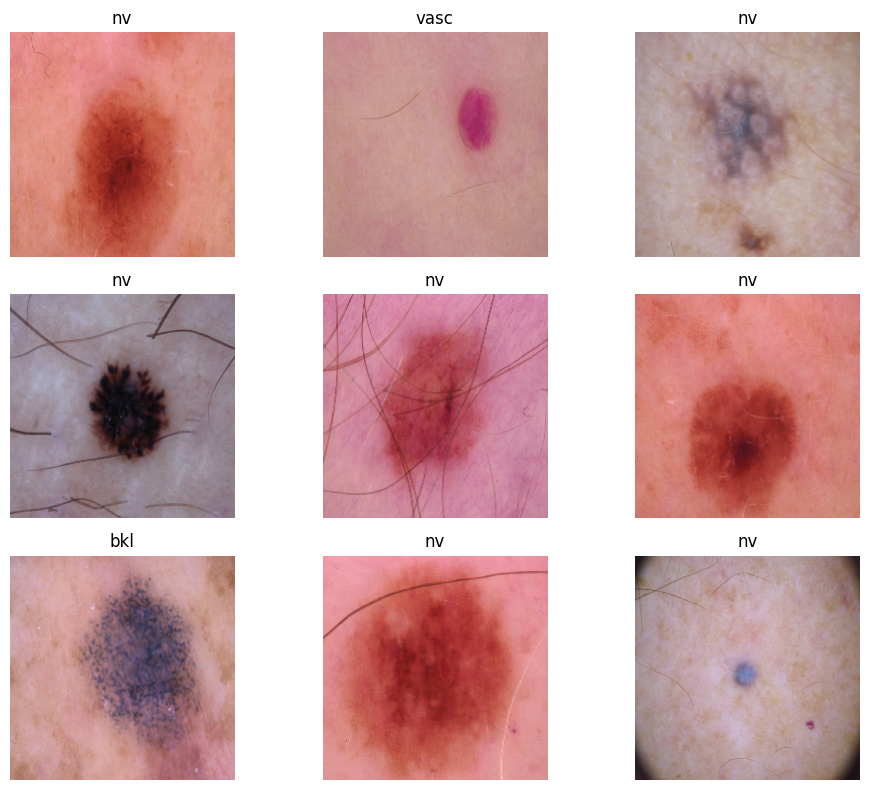

In [9]:
plt.figure(figsize=(10, 8))

for i in range(9):
    plt.subplot(3, 3, i + 1)
    plt.imshow(images[i].numpy().astype("uint8"))
    plt.title(label_encoder.inverse_transform([labels[i].numpy()])[0])
    plt.axis("off")

plt.tight_layout()
plt.show()

In [11]:
from tensorflow.keras import layers

In [18]:
# Cell 10 — Recreate augmentation correctly

data_augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal_and_vertical"),
    layers.RandomRotation(0.08),
    layers.RandomZoom(0.10),
    layers.RandomTranslation(
        height_factor=0.10,
        width_factor=0.10
    ),
    layers.RandomContrast(0.10),
], name="data_augmentation")

# Explicitly build it for 224 × 224 × 3
data_augmentation.build((None, 224, 224, 3))

print("Augmentation input shape:", data_augmentation.input_shape)

Augmentation input shape: (None, 224, 224, 3)


In [20]:
# Cell 11 — Test augmentation

sample_images, sample_labels = next(iter(train_ds))

augmented_images = data_augmentation(
    sample_images,
    training=True
)

print("Original shape :", sample_images.shape)
print("Augmented shape:", augmented_images.shape)

Original shape : (32, 224, 224, 3)
Augmented shape: (32, 224, 224, 3)


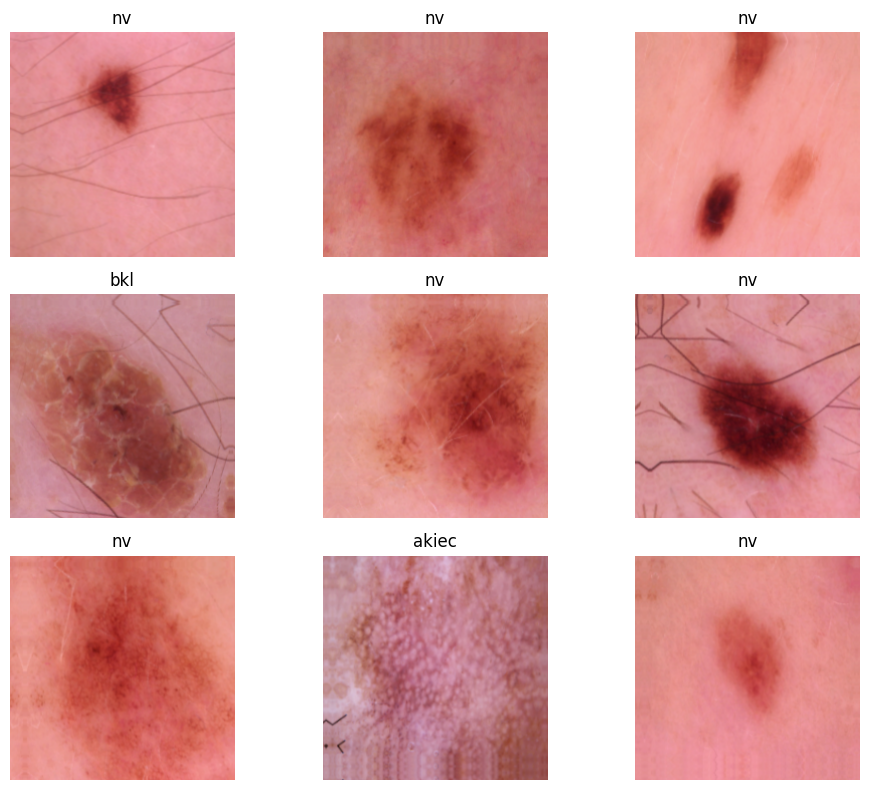

In [21]:
aug_images, aug_labels = next(iter(train_ds_aug))

plt.figure(figsize=(10, 8))

for i in range(9):
    plt.subplot(3, 3, i + 1)
    plt.imshow(
        tf.clip_by_value(
            aug_images[i],
            0,
            255
        ).numpy().astype("uint8")
    )
    plt.title(
        label_encoder.inverse_transform(
            [aug_labels[i].numpy()]
        )[0]
    )
    plt.axis("off")

plt.tight_layout()
plt.show()

In [22]:
# Cell 12 — ResNet50

from tensorflow.keras import layers, models, regularizers
from tensorflow.keras.applications import ResNet50
from tensorflow.keras.applications.resnet50 import preprocess_input
from tensorflow.keras.optimizers import Adam

resnet_base = ResNet50(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)

# Freeze ResNet50 for Stage 1
resnet_base.trainable = False

inputs = layers.Input(
    shape=(224, 224, 3),
    name="input_image"
)

# Augmentation
x = data_augmentation(inputs)

# ResNet50 preprocessing
x = layers.Lambda(
    preprocess_input,
    name="preprocess"
)(x)

# ResNet50 backbone
x = resnet_base(x, training=False)

# Classification head
x = layers.GlobalAveragePooling2D()(x)

x = layers.Dropout(0.5)(x)

x = layers.Dense(
    256,
    activation="relu",
    kernel_regularizer=regularizers.l2(0.0001)
)(x)

x = layers.Dropout(0.3)(x)

outputs = layers.Dense(
    7,
    activation="softmax",
    name="output"
)(x)

resnet_model = models.Model(
    inputs=inputs,
    outputs=outputs,
    name="ResNet50_HAM10000"
)

print("Input shape :", resnet_model.input_shape)
print("Output shape:", resnet_model.output_shape)

Input shape : (None, 224, 224, 3)
Output shape: (None, 7)


In [23]:
# Cell 13 — Compile ResNet50

resnet_model.compile(
    optimizer=Adam(
        learning_rate=1e-3,
        beta_1=0.9
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("ResNet50 compiled successfully.")

ResNet50 compiled successfully.


In [24]:
# Cell 14 — Train classification head

resnet_stage1_callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_accuracy",
        patience=2,
        mode="max",
        restore_best_weights=True,
        verbose=1
    ),

    tf.keras.callbacks.ModelCheckpoint(
        "/kaggle/working/resnet50_stage1.keras",
        monitor="val_accuracy",
        mode="max",
        save_best_only=True,
        verbose=1
    )
]

resnet_history_1 = resnet_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=5,
    callbacks=resnet_stage1_callbacks,
    verbose=1
)

Epoch 1/5
220/220 ━━━━━━━━━━━━━━━━━━━━ 0s 136ms/step - accuracy: 0.6461 - loss: 1.2502
Epoch 1: val_accuracy improved from None to 0.72655, saving model to /kaggle/working/resnet50_stage1.keras

Epoch 1: finished saving model to /kaggle/working/resnet50_stage1.keras
220/220 ━━━━━━━━━━━━━━━━━━━━ 51s 176ms/step - accuracy: 0.6785 - loss: 1.0180 - val_accuracy: 0.7265 - val_loss: 0.7782
Epoch 2/5
219/220 ━━━━━━━━━━━━━━━━━━━━ 0s 132ms/step - accuracy: 0.7271 - loss: 0.8314
Epoch 2: val_accuracy improved from 0.72655 to 0.73653, saving model to /kaggle/working/resnet50_stage1.keras

Epoch 2: finished saving model to /kaggle/working/resnet50_stage1.keras
220/220 ━━━━━━━━━━━━━━━━━━━━ 34s 156ms/step - accuracy: 0.7221 - loss: 0.8261 - val_accuracy: 0.7365 - val_loss: 0.7377
Epoch 3/5
219/220 ━━━━━━━━━━━━━━━━━━━━ 0s 135ms/step - accuracy: 0.7297 - loss: 0.7931
Epoch 3: val_accuracy improved from 0.73653 to 0.73952, saving model to /kaggle/working/resnet50_stage1.keras

Epoch 3: finished saving 

In [25]:
# Cell 15 — Fine-tuning setup

resnet_base.trainable = True

# Freeze the first layers and fine-tune the upper layers
for layer in resnet_base.layers[:-40]:
    layer.trainable = False

print("Total ResNet50 layers:", len(resnet_base.layers))
print(
    "Trainable ResNet50 layers:",
    sum(layer.trainable for layer in resnet_base.layers)
)

Total ResNet50 layers: 175
Trainable ResNet50 layers: 40


In [26]:
# Cell 16 — Recompile for fine-tuning

resnet_model.compile(
    optimizer=Adam(
        learning_rate=1e-5,
        beta_1=0.9
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("ResNet50 recompiled for fine-tuning.")

ResNet50 recompiled for fine-tuning.


In [27]:
# Cell 17 — Fine-tune ResNet50

resnet_stage2_callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_accuracy",
        patience=4,
        mode="max",
        restore_best_weights=True,
        verbose=1
    ),

    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=2,
        min_lr=1e-7,
        verbose=1
    ),

    tf.keras.callbacks.ModelCheckpoint(
        "/kaggle/working/best_resnet50_finetuned.keras",
        monitor="val_accuracy",
        mode="max",
        save_best_only=True,
        verbose=1
    )
]

resnet_history_2 = resnet_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=15,
    callbacks=resnet_stage2_callbacks,
    verbose=1
)

Epoch 1/15
220/220 ━━━━━━━━━━━━━━━━━━━━ 0s 203ms/step - accuracy: 0.7302 - loss: 0.8525
Epoch 1: val_accuracy improved from None to 0.77745, saving model to /kaggle/working/best_resnet50_finetuned.keras

Epoch 1: finished saving model to /kaggle/working/best_resnet50_finetuned.keras
220/220 ━━━━━━━━━━━━━━━━━━━━ 70s 243ms/step - accuracy: 0.7378 - loss: 0.7965 - val_accuracy: 0.7774 - val_loss: 0.6599 - learning_rate: 1.0000e-05
Epoch 2/15
219/220 ━━━━━━━━━━━━━━━━━━━━ 0s 203ms/step - accuracy: 0.7515 - loss: 0.7127
Epoch 2: val_accuracy improved from 0.77745 to 0.78443, saving model to /kaggle/working/best_resnet50_finetuned.keras

Epoch 2: finished saving model to /kaggle/working/best_resnet50_finetuned.keras
220/220 ━━━━━━━━━━━━━━━━━━━━ 51s 229ms/step - accuracy: 0.7578 - loss: 0.6986 - val_accuracy: 0.7844 - val_loss: 0.6270 - learning_rate: 1.0000e-05
Epoch 3/15
219/220 ━━━━━━━━━━━━━━━━━━━━ 0s 203ms/step - accuracy: 0.7756 - loss: 0.6542
Epoch 3: val_accuracy improved from 0.78443 t

In [29]:
# Evaluate the best ResNet50 model directly
# No need to load the .keras file again

test_loss, test_accuracy = resnet_model.evaluate(test_ds, verbose=1)

print(f"ResNet50 Test Accuracy: {test_accuracy * 100:.2f}%")
print(f"ResNet50 Test Loss: {test_loss:.4f}")

63/63 ━━━━━━━━━━━━━━━━━━━━ 10s 151ms/step - accuracy: 0.8263 - loss: 0.5314
ResNet50 Test Accuracy: 82.63%
ResNet50 Test Loss: 0.5314


Classification Report:
              precision    recall  f1-score   support

       akiec     0.6842    0.4000    0.5049        65
         bcc     0.6250    0.6311    0.6280       103
         bkl     0.6084    0.7273    0.6625       220
          df     0.7778    0.3043    0.4375        23
         mel     0.6686    0.5067    0.5765       223
          nv     0.9047    0.9418    0.9229      1341
        vasc     0.8750    0.7500    0.8077        28

    accuracy                         0.8263      2003
   macro avg     0.7348    0.6087    0.6486      2003
weighted avg     0.8225    0.8263    0.8198      2003



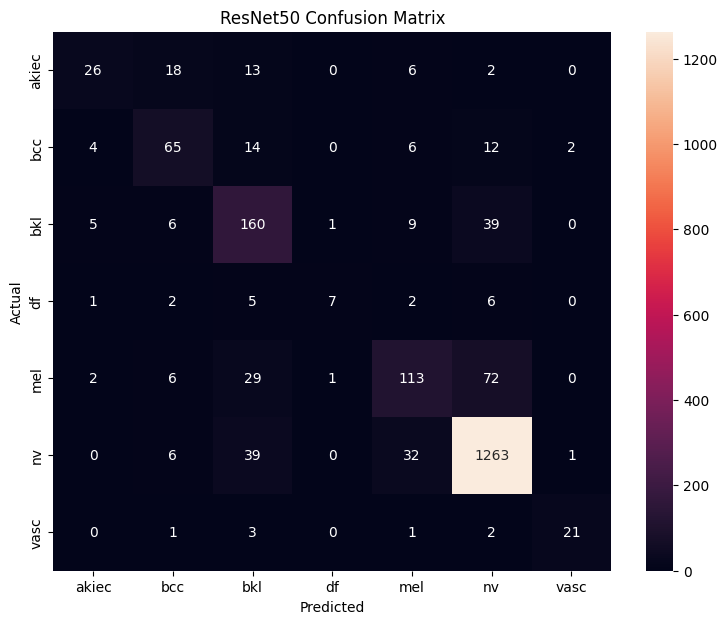

In [30]:
from sklearn.metrics import classification_report, confusion_matrix
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Get predictions
y_true = []
y_pred = []

for images, labels in test_ds:
    predictions = resnet_model.predict(images, verbose=0)
    y_true.extend(labels.numpy())
    y_pred.extend(np.argmax(predictions, axis=1))

y_true = np.array(y_true)
y_pred = np.array(y_pred)

# Classification report
print("Classification Report:")
print(
    classification_report(
        y_true,
        y_pred,
        target_names=label_encoder.classes_,
        digits=4
    )
)

# Confusion matrix
cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(9, 7))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    xticklabels=label_encoder.classes_,
    yticklabels=label_encoder.classes_
)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("ResNet50 Confusion Matrix")
plt.show()

In [31]:
from sklearn.utils.class_weight import compute_class_weight
import numpy as np

# Calculate class weights from TRAINING data only
classes = np.unique(train_labels)

class_weights_array = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=train_labels
)

class_weights = {
    int(cls): float(weight)
    for cls, weight in zip(classes, class_weights_array)
}

print("Class weights:")

for cls, weight in class_weights.items():
    print(
        f"{label_encoder.classes_[cls]:>5}: "
        f"{weight:.4f}"
    )

Class weights:
akiec: 4.3731
  bcc: 2.7817
  bkl: 1.3022
   df: 12.5179
  mel: 1.2855
   nv: 0.2134
 vasc: 10.0143


In [32]:
# Cap the class weights to avoid excessively large gradients
MAX_WEIGHT = 5.0

capped_class_weights = {
    cls: min(weight, MAX_WEIGHT)
    for cls, weight in class_weights.items()
}

print("Capped class weights:")

for cls, weight in capped_class_weights.items():
    print(f"{label_encoder.classes_[cls]:>5}: {weight:.4f}")

Capped class weights:
akiec: 4.3731
  bcc: 2.7817
  bkl: 1.3022
   df: 5.0000
  mel: 1.2855
   nv: 0.2134
 vasc: 5.0000


In [34]:
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau, ModelCheckpoint

In [35]:
# Fine-tune the existing best ResNet50 with capped class weights

resnet_base.trainable = True

for layer in resnet_base.layers[:-40]:
    layer.trainable = False

resnet_model.compile(
    optimizer=Adam(
        learning_rate=5e-6,
        beta_1=0.9
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

weighted_callbacks = [
    EarlyStopping(
        monitor="val_accuracy",
        patience=4,
        mode="max",
        restore_best_weights=True,
        verbose=1
    ),
    ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=2,
        min_lr=1e-7,
        verbose=1
    ),
    ModelCheckpoint(
        "/kaggle/working/best_resnet50_weighted.keras",
        monitor="val_accuracy",
        mode="max",
        save_best_only=True,
        verbose=1
    )
]

weighted_history = resnet_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10,
    class_weight=capped_class_weights,
    callbacks=weighted_callbacks,
    verbose=1
)

Epoch 1/10
219/220 ━━━━━━━━━━━━━━━━━━━━ 0s 202ms/step - accuracy: 0.8352 - loss: 0.7392
Epoch 1: val_accuracy improved from None to 0.78144, saving model to /kaggle/working/best_resnet50_weighted.keras

Epoch 1: finished saving model to /kaggle/working/best_resnet50_weighted.keras
220/220 ━━━━━━━━━━━━━━━━━━━━ 68s 239ms/step - accuracy: 0.8314 - loss: 0.7025 - val_accuracy: 0.7814 - val_loss: 0.6153 - learning_rate: 5.0000e-06
Epoch 2/10
219/220 ━━━━━━━━━━━━━━━━━━━━ 0s 204ms/step - accuracy: 0.8153 - loss: 0.6889
Epoch 2: val_accuracy did not improve from 0.78144
220/220 ━━━━━━━━━━━━━━━━━━━━ 49s 221ms/step - accuracy: 0.8141 - loss: 0.6585 - val_accuracy: 0.7735 - val_loss: 0.6419 - learning_rate: 5.0000e-06
Epoch 3/10
219/220 ━━━━━━━━━━━━━━━━━━━━ 0s 203ms/step - accuracy: 0.8158 - loss: 0.5816
Epoch 3: ReduceLROnPlateau reducing learning rate to 2.499999936844688e-06.

Epoch 3: val_accuracy did not improve from 0.78144
220/220 ━━━━━━━━━━━━━━━━━━━━ 49s 221ms/step - accuracy: 0.8107 - lo

In [36]:
# Rebuild the original ResNet50 model

from tensorflow.keras import layers, models, regularizers
from tensorflow.keras.applications import ResNet50
from tensorflow.keras.applications.resnet50 import preprocess_input
from tensorflow.keras.optimizers import Adam

# Create a fresh ResNet50 backbone
resnet_base = ResNet50(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)

resnet_base.trainable = False

# Build the same architecture
inputs = layers.Input(
    shape=(224, 224, 3),
    name="input_image"
)

x = data_augmentation(inputs)

# Use a Lambda again for consistency with the original model
x = layers.Lambda(
    preprocess_input,
    name="preprocess"
)(x)

x = resnet_base(x, training=False)

x = layers.GlobalAveragePooling2D()(x)

x = layers.Dropout(0.5)(x)

x = layers.Dense(
    256,
    activation="relu",
    kernel_regularizer=regularizers.l2(0.0001)
)(x)

x = layers.Dropout(0.3)(x)

outputs = layers.Dense(
    7,
    activation="softmax",
    name="output"
)(x)

resnet_model = models.Model(
    inputs=inputs,
    outputs=outputs,
    name="ResNet50_HAM10000"
)

print("Original ResNet50 architecture rebuilt.")

Original ResNet50 architecture rebuilt.


In [37]:
# Load the Stage-1 best weights
resnet_model.load_weights(
    "/kaggle/working/resnet50_stage1.keras"
)

print("Stage-1 weights loaded successfully.")

Stage-1 weights loaded successfully.


In [38]:
# Fine-tune exactly as before, without class weighting

resnet_base.trainable = True

for layer in resnet_base.layers[:-40]:
    layer.trainable = False

resnet_model.compile(
    optimizer=Adam(
        learning_rate=1e-5,
        beta_1=0.9
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

resnet_callbacks = [
    EarlyStopping(
        monitor="val_accuracy",
        patience=4,
        mode="max",
        restore_best_weights=True,
        verbose=1
    ),
    ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=2,
        min_lr=1e-7,
        verbose=1
    ),
    ModelCheckpoint(
        "/kaggle/working/best_resnet50_finetuned_v2.keras",
        monitor="val_accuracy",
        mode="max",
        save_best_only=True,
        verbose=1
    )
]

resnet_history_2 = resnet_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=15,
    callbacks=resnet_callbacks,
    verbose=1
)

Epoch 1/15
219/220 ━━━━━━━━━━━━━━━━━━━━ 0s 202ms/step - accuracy: 0.7228 - loss: 0.8447
Epoch 1: val_accuracy improved from None to 0.78244, saving model to /kaggle/working/best_resnet50_finetuned_v2.keras

Epoch 1: finished saving model to /kaggle/working/best_resnet50_finetuned_v2.keras
220/220 ━━━━━━━━━━━━━━━━━━━━ 68s 238ms/step - accuracy: 0.7361 - loss: 0.7966 - val_accuracy: 0.7824 - val_loss: 0.6649 - learning_rate: 1.0000e-05
Epoch 2/15
219/220 ━━━━━━━━━━━━━━━━━━━━ 0s 203ms/step - accuracy: 0.7669 - loss: 0.7000
Epoch 2: val_accuracy improved from 0.78244 to 0.78343, saving model to /kaggle/working/best_resnet50_finetuned_v2.keras

Epoch 2: finished saving model to /kaggle/working/best_resnet50_finetuned_v2.keras
220/220 ━━━━━━━━━━━━━━━━━━━━ 50s 228ms/step - accuracy: 0.7666 - loss: 0.6945 - val_accuracy: 0.7834 - val_loss: 0.6257 - learning_rate: 1.0000e-05
Epoch 3/15
219/220 ━━━━━━━━━━━━━━━━━━━━ 0s 203ms/step - accuracy: 0.7878 - loss: 0.6401
Epoch 3: val_accuracy improved fr

In [39]:
import os

print(
    "Original checkpoint exists:",
    os.path.exists("/kaggle/working/best_resnet50_finetuned.keras")
)

print(
    "Stage-1 checkpoint exists:",
    os.path.exists("/kaggle/working/resnet50_stage1.keras")
)

Original checkpoint exists: True
Stage-1 checkpoint exists: True


In [40]:
import os

for path in [
    "/kaggle/working/resnet50_stage1.keras",
    "/kaggle/working/best_resnet50_finetuned.keras"
]:
    size_mb = os.path.getsize(path) / (1024 * 1024)
    print(f"{os.path.basename(path)}: {size_mb:.2f} MB")

resnet50_stage1.keras: 96.66 MB
best_resnet50_finetuned.keras: 217.48 MB


In [41]:
# Rebuild the ResNet50 architecture and load the best fine-tuned weights

from tensorflow.keras import layers, models, regularizers
from tensorflow.keras.applications import ResNet50
from tensorflow.keras.applications.resnet50 import preprocess_input

# Fresh ResNet50 backbone
resnet_base = ResNet50(
    weights=None,
    include_top=False,
    input_shape=(224, 224, 3)
)

# Build the same architecture
inputs = layers.Input(
    shape=(224, 224, 3),
    name="input_image"
)

x = data_augmentation(inputs)

x = layers.Lambda(
    preprocess_input,
    name="preprocess"
)(x)

x = resnet_base(x, training=False)

x = layers.GlobalAveragePooling2D()(x)

x = layers.Dropout(0.5)(x)

x = layers.Dense(
    256,
    activation="relu",
    kernel_regularizer=regularizers.l2(0.0001)
)(x)

x = layers.Dropout(0.3)(x)

outputs = layers.Dense(
    7,
    activation="softmax",
    name="output"
)(x)

resnet_model = models.Model(
    inputs=inputs,
    outputs=outputs,
    name="ResNet50_HAM10000"
)

print("Model rebuilt successfully.")

Model rebuilt successfully.


In [42]:
# Load the original best fine-tuned weights

resnet_model.load_weights(
    "/kaggle/working/best_resnet50_finetuned.keras"
)

print("Best fine-tuned weights loaded successfully.")

Best fine-tuned weights loaded successfully.


In [44]:
from tensorflow.keras.optimizers import Adam

# Compile the recovered best model
resnet_model.compile(
    optimizer=Adam(
        learning_rate=1e-5,
        beta_1=0.9
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("Recovered model compiled successfully.")

Recovered model compiled successfully.


In [45]:
val_loss, val_accuracy = resnet_model.evaluate(
    val_ds,
    verbose=1
)

print(f"Recovered ResNet50 Validation Accuracy: {val_accuracy * 100:.2f}%")
print(f"Recovered ResNet50 Validation Loss: {val_loss:.4f}")

32/32 ━━━━━━━━━━━━━━━━━━━━ 8s 119ms/step - accuracy: 0.8323 - loss: 0.5292
Recovered ResNet50 Validation Accuracy: 83.23%
Recovered ResNet50 Validation Loss: 0.5292


In [46]:
# Moderate class weights
# Class order:
# 0=akiec, 1=bcc, 2=bkl, 3=df, 4=mel, 5=nv, 6=vasc

moderate_class_weights = {
    0: 2.0,   # akiec
    1: 1.8,   # bcc
    2: 1.2,   # bkl
    3: 2.5,   # df
    4: 1.3,   # mel
    5: 1.0,   # nv
    6: 2.5    # vasc
}

print("Moderate class weights:")

for cls, weight in moderate_class_weights.items():
    print(f"{label_encoder.classes_[cls]:>5}: {weight:.2f}")

Moderate class weights:
akiec: 2.00
  bcc: 1.80
  bkl: 1.20
   df: 2.50
  mel: 1.30
   nv: 1.00
 vasc: 2.50


In [47]:
# Moderate class-weight fine-tuning

from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau, ModelCheckpoint
from tensorflow.keras.optimizers import Adam

# Keep the same fine-tuning configuration
resnet_base.trainable = True

for layer in resnet_base.layers[:-40]:
    layer.trainable = False

# Very small learning rate to protect the existing good weights
resnet_model.compile(
    optimizer=Adam(
        learning_rate=2e-6,
        beta_1=0.9
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

moderate_callbacks = [
    EarlyStopping(
        monitor="val_accuracy",
        patience=4,
        mode="max",
        restore_best_weights=True,
        verbose=1
    ),
    ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=2,
        min_lr=1e-7,
        verbose=1
    ),
    ModelCheckpoint(
        "/kaggle/working/best_resnet50_moderate_weighted.keras",
        monitor="val_accuracy",
        mode="max",
        save_best_only=True,
        verbose=1
    )
]

moderate_history = resnet_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10,
    class_weight=moderate_class_weights,
    callbacks=moderate_callbacks,
    verbose=1
)

Epoch 1/10
219/220 ━━━━━━━━━━━━━━━━━━━━ 0s 201ms/step - accuracy: 0.8380 - loss: 0.6585
Epoch 1: val_accuracy improved from None to 0.82735, saving model to /kaggle/working/best_resnet50_moderate_weighted.keras

Epoch 1: finished saving model to /kaggle/working/best_resnet50_moderate_weighted.keras
220/220 ━━━━━━━━━━━━━━━━━━━━ 68s 238ms/step - accuracy: 0.8412 - loss: 0.6332 - val_accuracy: 0.8273 - val_loss: 0.5314 - learning_rate: 2.0000e-06
Epoch 2/10
219/220 ━━━━━━━━━━━━━━━━━━━━ 0s 204ms/step - accuracy: 0.8451 - loss: 0.6215
Epoch 2: val_accuracy did not improve from 0.82735
220/220 ━━━━━━━━━━━━━━━━━━━━ 49s 222ms/step - accuracy: 0.8397 - loss: 0.6275 - val_accuracy: 0.8234 - val_loss: 0.5286 - learning_rate: 2.0000e-06
Epoch 3/10
219/220 ━━━━━━━━━━━━━━━━━━━━ 0s 203ms/step - accuracy: 0.8428 - loss: 0.6275
Epoch 3: val_accuracy did not improve from 0.82735
220/220 ━━━━━━━━━━━━━━━━━━━━ 49s 221ms/step - accuracy: 0.8442 - loss: 0.6190 - val_accuracy: 0.8263 - val_loss: 0.5296 - lear

In [48]:
# Evaluate the best moderate-weighted model on validation data

val_loss_moderate, val_accuracy_moderate = resnet_model.evaluate(
    val_ds,
    verbose=1
)

print(f"Moderate-weight Validation Accuracy: {val_accuracy_moderate * 100:.2f}%")
print(f"Moderate-weight Validation Loss: {val_loss_moderate:.4f}")

32/32 ━━━━━━━━━━━━━━━━━━━━ 4s 121ms/step - accuracy: 0.8343 - loss: 0.5250
Moderate-weight Validation Accuracy: 83.43%
Moderate-weight Validation Loss: 0.5250


In [49]:
from sklearn.metrics import classification_report, confusion_matrix
import numpy as np

# Generate validation predictions
y_val_true = []
y_val_pred = []

for images, labels in val_ds:
    predictions = resnet_model.predict(images, verbose=0)
    y_val_true.extend(labels.numpy())
    y_val_pred.extend(np.argmax(predictions, axis=1))

y_val_true = np.array(y_val_true)
y_val_pred = np.array(y_val_pred)

# Classification report
print("Moderate-weight Validation Classification Report:\n")

print(
    classification_report(
        y_val_true,
        y_val_pred,
        target_names=label_encoder.classes_,
        digits=4
    )
)

Moderate-weight Validation Classification Report:

              precision    recall  f1-score   support

       akiec     0.6667    0.4242    0.5185        33
         bcc     0.6724    0.7647    0.7156        51
         bkl     0.5704    0.7364    0.6429       110
          df     0.6667    0.5000    0.5714        12
         mel     0.7000    0.6306    0.6635       111
          nv     0.9334    0.9195    0.9264       671
        vasc     0.8182    0.6429    0.7200        14

    accuracy                         0.8343      1002
   macro avg     0.7183    0.6598    0.6798      1002
weighted avg     0.8408    0.8343    0.8349      1002



In [50]:
# Save the current best moderate-weight model weights

resnet_model.save_weights(
    "/kaggle/working/resnet50_moderate_best.weights.h5"
)

print("Candidate model weights saved successfully.")

Candidate model weights saved successfully.


In [51]:
# Evaluate the moderate-weight candidate on the test set

test_loss_moderate, test_accuracy_moderate = resnet_model.evaluate(
    test_ds,
    verbose=1
)

print(f"Moderate-weight Test Accuracy: {test_accuracy_moderate * 100:.2f}%")
print(f"Moderate-weight Test Loss: {test_loss_moderate:.4f}")

63/63 ━━━━━━━━━━━━━━━━━━━━ 8s 121ms/step - accuracy: 0.8243 - loss: 0.5278
Moderate-weight Test Accuracy: 82.43%
Moderate-weight Test Loss: 0.5278


In [52]:
from sklearn.metrics import classification_report, confusion_matrix
import numpy as np

# Predictions on untouched test set
y_true = []
y_pred = []

for images, labels in test_ds:
    predictions = resnet_model.predict(images, verbose=0)
    y_true.extend(labels.numpy())
    y_pred.extend(np.argmax(predictions, axis=1))

y_true = np.array(y_true)
y_pred = np.array(y_pred)

print("Moderate-weight Test Classification Report:\n")
print(
    classification_report(
        y_true,
        y_pred,
        target_names=label_encoder.classes_,
        digits=4
    )
)

Moderate-weight Test Classification Report:

              precision    recall  f1-score   support

       akiec     0.6444    0.4462    0.5273        65
         bcc     0.5983    0.6796    0.6364       103
         bkl     0.5950    0.7545    0.6653       220
          df     0.7692    0.4348    0.5556        23
         mel     0.6313    0.5605    0.5938       223
          nv     0.9261    0.9165    0.9213      1341
        vasc     0.9167    0.7857    0.8462        28

    accuracy                         0.8243      2003
   macro avg     0.7259    0.6540    0.6780      2003
weighted avg     0.8290    0.8243    0.8240      2003



In [53]:
cm = confusion_matrix(y_true, y_pred)

print("Confusion Matrix:")
print(cm)

Confusion Matrix:
[[  29   18   11    0    5    2    0]
 [   5   70   11    0    7    9    1]
 [   7   10  166    1   11   25    0]
 [   1    2    5   10    2    3    0]
 [   3    6   30    1  125   58    0]
 [   0    9   54    1   47 1229    1]
 [   0    2    2    0    1    1   22]]


In [55]:
# ============================================
# STEP 1: Balance TRAINING data toward 1200/class
# ============================================

TARGET_PER_CLASS = 1200

balanced_parts = []

for class_name in sorted(train["dx"].unique()):
    class_df = train[train["dx"] == class_name].copy()

    if len(class_df) < TARGET_PER_CLASS:
        # Oversample minority classes with replacement
        extra_df = class_df.sample(
            n=TARGET_PER_CLASS - len(class_df),
            replace=True,
            random_state=42
        )

        class_balanced = pd.concat(
            [class_df, extra_df],
            ignore_index=True
        )
    else:
        # Keep all samples if already >= 1200
        class_balanced = class_df.copy()

    balanced_parts.append(class_balanced)

# Combine and shuffle
balanced_train = pd.concat(
    balanced_parts,
    ignore_index=True
).sample(
    frac=1,
    random_state=42
).reset_index(drop=True)

print("Original training size:", len(train))
print("Balanced training size:", len(balanced_train))

print("\nOriginal class distribution:")
print(train["dx"].value_counts().sort_index())

print("\nBalanced class distribution:")
print(balanced_train["dx"].value_counts().sort_index())

Original training size: 7010
Balanced training size: 11893

Original class distribution:
dx
akiec     229
bcc       360
bkl       769
df         80
mel       779
nv       4693
vasc      100
Name: count, dtype: int64

Balanced class distribution:
dx
akiec    1200
bcc      1200
bkl      1200
df       1200
mel      1200
nv       4693
vasc     1200
Name: count, dtype: int64


In [56]:
# ============================================
# STEP 2: Create balanced TensorFlow dataset
# ============================================

balanced_train_paths = balanced_train["image_path"].values

balanced_train_labels = label_encoder.transform(
    balanced_train["dx"]
).astype("int32")

balanced_train_ds = tf.data.Dataset.from_tensor_slices(
    (balanced_train_paths, balanced_train_labels)
)

balanced_train_ds = (
    balanced_train_ds
    .shuffle(
        len(balanced_train),
        seed=42,
        reshuffle_each_iteration=True
    )
    .map(
        load_image,
        num_parallel_calls=AUTOTUNE
    )
    .batch(BATCH_SIZE)
    .prefetch(AUTOTUNE)
)

print("Balanced dataset created successfully.")
print("Number of samples:", len(balanced_train))
print("Batch size:", BATCH_SIZE)

Balanced dataset created successfully.
Number of samples: 11893
Batch size: 32


In [57]:
for images, labels in balanced_train_ds.take(1):
    print("Image batch shape:", images.shape)
    print("Label batch shape:", labels.shape)
    print("First 10 labels:", labels.numpy()[:10])

Image batch shape: (32, 224, 224, 3)
Label batch shape: (32,)
First 10 labels: [3 6 5 0 0 5 1 5 5 1]


In [58]:
# ============================================
# STEP 3: Paper-aligned data augmentation
# ============================================

paper_augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal_and_vertical"),
    layers.RandomRotation(0.08),
    layers.RandomZoom(0.10),
    layers.RandomTranslation(
        height_factor=0.10,
        width_factor=0.10
    ),
    layers.RandomContrast(0.15),
    layers.RandomBrightness(
        factor=0.10,
        value_range=(0, 255)
    ),
], name="paper_augmentation")

print("Paper-aligned augmentation created.")

Paper-aligned augmentation created.


In [59]:
for images, labels in balanced_train_ds.take(1):
    augmented_images = paper_augmentation(images, training=True)

    print("Original shape:", images.shape)
    print("Augmented shape:", augmented_images.shape)
    print("Original pixel range:",
          float(tf.reduce_min(images)),
          "to",
          float(tf.reduce_max(images)))
    print("Augmented pixel range:",
          float(tf.reduce_min(augmented_images)),
          "to",
          float(tf.reduce_max(augmented_images)))

Original shape: (32, 224, 224, 3)
Augmented shape: (32, 224, 224, 3)
Original pixel range: 0.0 to 254.48211669921875
Augmented pixel range: 0.0 to 255.0


In [60]:
# ============================================
# STEP 4: Build ResNet50 for balanced training
# ============================================

# Load ImageNet-pretrained ResNet50
balanced_resnet_base = ResNet50(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)

# Freeze base for initial training
balanced_resnet_base.trainable = False

# Build model
inputs = layers.Input(
    shape=(224, 224, 3),
    name="input_image"
)

x = paper_augmentation(inputs)

x = layers.Lambda(
    preprocess_input,
    name="preprocess"
)(x)

x = balanced_resnet_base(
    x,
    training=False
)

x = layers.GlobalAveragePooling2D()(x)

x = layers.Dropout(0.5)(x)

x = layers.Dense(
    256,
    activation="relu",
    kernel_regularizer=regularizers.l2(0.0001)
)(x)

x = layers.Dropout(0.3)(x)

outputs = layers.Dense(
    7,
    activation="softmax",
    name="output"
)(x)

balanced_resnet_model = models.Model(
    inputs=inputs,
    outputs=outputs,
    name="ResNet50_HAM10000_Balanced"
)

print("Model created successfully.")
print("Total parameters:", balanced_resnet_model.count_params())

Model created successfully.
Total parameters: 24114055


In [61]:
# ============================================
# STEP 4B: Compile model
# ============================================

balanced_resnet_model.compile(
    optimizer=Adam(
        learning_rate=1e-4,
        beta_1=0.9
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

balanced_resnet_model.summary()

Model: "ResNet50_HAM10000_Balanced"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_image (InputLayer)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ paper_augmentation (Sequential) │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ preprocess (Lambda)             │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ resnet50 (Functional)           │ (None, 7, 7, 2048)     │    23,587,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_4      │ (None, 2048)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_8 (Dropout)             │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 256)            │       524,544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_9 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output (Dense)                  │ (None, 7)              │         1,799 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 24,114,055 (91.99 MB)

 Trainable params: 526,343 (2.01 MB)

 Non-trainable params: 23,587,712 (89.98 MB)

In [62]:
# ============================================
# STEP 5: Initial training on balanced dataset
# ============================================

balanced_stage1_checkpoint = "/kaggle/working/balanced_resnet50_stage1.keras"

balanced_stage1_callbacks = [
    EarlyStopping(
        monitor="val_accuracy",
        patience=3,
        mode="max",
        restore_best_weights=True,
        verbose=1
    ),

    ModelCheckpoint(
        balanced_stage1_checkpoint,
        monitor="val_accuracy",
        mode="max",
        save_best_only=True,
        verbose=1
    ),

    ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=2,
        min_lr=1e-6,
        verbose=1
    )
]

balanced_stage1_history = balanced_resnet_model.fit(
    balanced_train_ds,
    validation_data=val_ds,
    epochs=10,
    callbacks=balanced_stage1_callbacks,
    verbose=1
)

Epoch 1/10
372/372 ━━━━━━━━━━━━━━━━━━━━ 0s 134ms/step - accuracy: 0.3626 - loss: 2.0448
Epoch 1: val_accuracy improved from None to 0.71657, saving model to /kaggle/working/balanced_resnet50_stage1.keras

Epoch 1: finished saving model to /kaggle/working/balanced_resnet50_stage1.keras
372/372 ━━━━━━━━━━━━━━━━━━━━ 66s 155ms/step - accuracy: 0.4384 - loss: 1.7146 - val_accuracy: 0.7166 - val_loss: 0.8907 - learning_rate: 1.0000e-04
Epoch 2/10
372/372 ━━━━━━━━━━━━━━━━━━━━ 0s 134ms/step - accuracy: 0.5389 - loss: 1.2975
Epoch 2: val_accuracy did not improve from 0.71657
372/372 ━━━━━━━━━━━━━━━━━━━━ 54s 145ms/step - accuracy: 0.5491 - loss: 1.2664 - val_accuracy: 0.7076 - val_loss: 0.8860 - learning_rate: 1.0000e-04
Epoch 3/10
372/372 ━━━━━━━━━━━━━━━━━━━━ 0s 134ms/step - accuracy: 0.5893 - loss: 1.1495
Epoch 3: val_accuracy improved from 0.71657 to 0.72255, saving model to /kaggle/working/balanced_resnet50_stage1.keras

Epoch 3: finished saving model to /kaggle/working/balanced_resnet50_sta

In [63]:
# ============================================
# STEP 6: Fine-tune last 40 ResNet50 layers
# ============================================

balanced_resnet_base.trainable = True

# Freeze all except the last 40 layers
for layer in balanced_resnet_base.layers[:-40]:
    layer.trainable = False

print("Trainable ResNet50 layers:")

for layer in balanced_resnet_base.layers:
    if layer.trainable:
        print(layer.name)

print(
    "\nTrainable parameters:",
    sum(
        np.prod(layer.shape)
        for layer in balanced_resnet_model.trainable_weights
    )
)

Trainable ResNet50 layers:
conv4_block6_1_relu
conv4_block6_2_conv
conv4_block6_2_bn
conv4_block6_2_relu
conv4_block6_3_conv
conv4_block6_3_bn
conv4_block6_add
conv4_block6_out
conv5_block1_1_conv
conv5_block1_1_bn
conv5_block1_1_relu
conv5_block1_2_conv
conv5_block1_2_bn
conv5_block1_2_relu
conv5_block1_0_conv
conv5_block1_3_conv
conv5_block1_0_bn
conv5_block1_3_bn
conv5_block1_add
conv5_block1_out
conv5_block2_1_conv
conv5_block2_1_bn
conv5_block2_1_relu
conv5_block2_2_conv
conv5_block2_2_bn
conv5_block2_2_relu
conv5_block2_3_conv
conv5_block2_3_bn
conv5_block2_add
conv5_block2_out
conv5_block3_1_conv
conv5_block3_1_bn
conv5_block3_1_relu
conv5_block3_2_conv
conv5_block3_2_bn
conv5_block3_2_relu
conv5_block3_3_conv
conv5_block3_3_bn
conv5_block3_add
conv5_block3_out

Trainable parameters: 16358151


In [64]:
# ============================================
# STEP 6B: Recompile for fine-tuning
# ============================================

balanced_resnet_model.compile(
    optimizer=Adam(
        learning_rate=1e-5,
        beta_1=0.9
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("Model recompiled for fine-tuning.")

Model recompiled for fine-tuning.


In [65]:
# ============================================
# STEP 7: Fine-tune balanced ResNet50
# ============================================

balanced_finetune_checkpoint = (
    "/kaggle/working/best_balanced_resnet50_finetuned.keras"
)

balanced_finetune_callbacks = [
    EarlyStopping(
        monitor="val_accuracy",
        patience=4,
        mode="max",
        restore_best_weights=True,
        verbose=1
    ),

    ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=2,
        min_lr=1e-7,
        verbose=1
    ),

    ModelCheckpoint(
        balanced_finetune_checkpoint,
        monitor="val_accuracy",
        mode="max",
        save_best_only=True,
        verbose=1
    )
]

balanced_finetune_history = balanced_resnet_model.fit(
    balanced_train_ds,
    validation_data=val_ds,
    epochs=15,
    callbacks=balanced_finetune_callbacks,
    verbose=1
)

Epoch 1/15
372/372 ━━━━━━━━━━━━━━━━━━━━ 0s 205ms/step - accuracy: 0.6315 - loss: 1.0404
Epoch 1: val_accuracy improved from None to 0.74751, saving model to /kaggle/working/best_balanced_resnet50_finetuned.keras

Epoch 1: finished saving model to /kaggle/working/best_balanced_resnet50_finetuned.keras
372/372 ━━━━━━━━━━━━━━━━━━━━ 101s 228ms/step - accuracy: 0.6647 - loss: 0.9453 - val_accuracy: 0.7475 - val_loss: 0.7262 - learning_rate: 1.0000e-05
Epoch 2/15
372/372 ━━━━━━━━━━━━━━━━━━━━ 0s 204ms/step - accuracy: 0.7309 - loss: 0.7786
Epoch 2: val_accuracy improved from 0.74751 to 0.75649, saving model to /kaggle/working/best_balanced_resnet50_finetuned.keras

Epoch 2: finished saving model to /kaggle/working/best_balanced_resnet50_finetuned.keras
372/372 ━━━━━━━━━━━━━━━━━━━━ 82s 219ms/step - accuracy: 0.7373 - loss: 0.7588 - val_accuracy: 0.7565 - val_loss: 0.6931 - learning_rate: 1.0000e-05
Epoch 3/15
372/372 ━━━━━━━━━━━━━━━━━━━━ 0s 204ms/step - accuracy: 0.7716 - loss: 0.6678
Epoch 3:

In [66]:
# Continue fine-tuning with a smaller learning rate

balanced_resnet_model.compile(
    optimizer=Adam(
        learning_rate=5e-7,
        beta_1=0.9
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

continued_callbacks = [
    EarlyStopping(
        monitor="val_accuracy",
        patience=5,
        mode="max",
        restore_best_weights=True,
        verbose=1
    ),

    ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=2,
        min_lr=1e-8,
        verbose=1
    ),

    ModelCheckpoint(
        "/kaggle/working/best_balanced_resnet50_continued.keras",
        monitor="val_accuracy",
        mode="max",
        save_best_only=True,
        verbose=1
    )
]

continued_history = balanced_resnet_model.fit(
    balanced_train_ds,
    validation_data=val_ds,
    epochs=10,
    callbacks=continued_callbacks,
    verbose=1
)

Epoch 1/10
372/372 ━━━━━━━━━━━━━━━━━━━━ 0s 203ms/step - accuracy: 0.9139 - loss: 0.2800
Epoch 1: val_accuracy improved from None to 0.81936, saving model to /kaggle/working/best_balanced_resnet50_continued.keras

Epoch 1: finished saving model to /kaggle/working/best_balanced_resnet50_continued.keras
372/372 ━━━━━━━━━━━━━━━━━━━━ 99s 225ms/step - accuracy: 0.9134 - loss: 0.2812 - val_accuracy: 0.8194 - val_loss: 0.6152 - learning_rate: 5.0000e-07
Epoch 2/10
372/372 ━━━━━━━━━━━━━━━━━━━━ 0s 204ms/step - accuracy: 0.9198 - loss: 0.2724
Epoch 2: val_accuracy improved from 0.81936 to 0.82335, saving model to /kaggle/working/best_balanced_resnet50_continued.keras

Epoch 2: finished saving model to /kaggle/working/best_balanced_resnet50_continued.keras
372/372 ━━━━━━━━━━━━━━━━━━━━ 82s 219ms/step - accuracy: 0.9174 - loss: 0.2750 - val_accuracy: 0.8234 - val_loss: 0.6147 - learning_rate: 5.0000e-07
Epoch 3/10
372/372 ━━━━━━━━━━━━━━━━━━━━ 0s 204ms/step - accuracy: 0.9214 - loss: 0.2740
Epoch 3: 

In [67]:
# ============================================
# STEP 8: FINAL TEST EVALUATION
# ============================================

balanced_test_loss, balanced_test_accuracy = (
    balanced_resnet_model.evaluate(
        test_ds,
        verbose=1
    )
)

print(
    f"Balanced + Fine-tuned Test Accuracy: "
    f"{balanced_test_accuracy * 100:.2f}%"
)

print(
    f"Balanced + Fine-tuned Test Loss: "
    f"{balanced_test_loss:.4f}"
)

63/63 ━━━━━━━━━━━━━━━━━━━━ 8s 123ms/step - accuracy: 0.8248 - loss: 0.5962
Balanced + Fine-tuned Test Accuracy: 82.48%
Balanced + Fine-tuned Test Loss: 0.5962


In [68]:
# ============================================
# STEP 11: Extended fine-tuning — up to 15 epochs
# ============================================

balanced_resnet_model.compile(
    optimizer=Adam(
        learning_rate=2.5e-7,
        beta_1=0.9
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

extended_callbacks = [
    EarlyStopping(
        monitor="val_accuracy",
        patience=5,
        mode="max",
        restore_best_weights=True,
        verbose=1
    ),

    ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=2,
        min_lr=1e-8,
        verbose=1
    ),

    ModelCheckpoint(
        "/kaggle/working/best_balanced_resnet50_extended.keras",
        monitor="val_accuracy",
        mode="max",
        save_best_only=True,
        verbose=1
    )
]

extended_history = balanced_resnet_model.fit(
    balanced_train_ds,
    validation_data=val_ds,
    epochs=15,
    callbacks=extended_callbacks,
    verbose=1
)

Epoch 1/15
372/372 ━━━━━━━━━━━━━━━━━━━━ 0s 203ms/step - accuracy: 0.9154 - loss: 0.2737
Epoch 1: val_accuracy improved from None to 0.82435, saving model to /kaggle/working/best_balanced_resnet50_extended.keras

Epoch 1: finished saving model to /kaggle/working/best_balanced_resnet50_extended.keras
372/372 ━━━━━━━━━━━━━━━━━━━━ 98s 226ms/step - accuracy: 0.9180 - loss: 0.2684 - val_accuracy: 0.8244 - val_loss: 0.6114 - learning_rate: 2.5000e-07
Epoch 2/15
372/372 ━━━━━━━━━━━━━━━━━━━━ 0s 204ms/step - accuracy: 0.9136 - loss: 0.2843
Epoch 2: val_accuracy did not improve from 0.82435
372/372 ━━━━━━━━━━━━━━━━━━━━ 80s 215ms/step - accuracy: 0.9138 - loss: 0.2815 - val_accuracy: 0.8204 - val_loss: 0.6151 - learning_rate: 2.5000e-07
Epoch 3/15
372/372 ━━━━━━━━━━━━━━━━━━━━ 0s 204ms/step - accuracy: 0.9218 - loss: 0.2590
Epoch 3: ReduceLROnPlateau reducing learning rate to 1.2499999968440534e-07.

Epoch 3: val_accuracy did not improve from 0.82435
372/372 ━━━━━━━━━━━━━━━━━━━━ 80s 215ms/step - ac

In [69]:
# ============================================
# EXPERIMENT 2 — STEP 1
# Stronger HAM10000 augmentation
# ============================================

strong_augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal_and_vertical"),
    layers.RandomRotation(0.12),
    layers.RandomZoom(
        height_factor=(-0.15, 0.15),
        width_factor=(-0.15, 0.15)
    ),
    layers.RandomTranslation(
        height_factor=0.10,
        width_factor=0.10
    ),
    layers.RandomContrast(0.20),
    layers.RandomBrightness(
        factor=0.15,
        value_range=(0, 255)
    ),
], name="strong_augmentation")

print("Strong augmentation created successfully.")

Strong augmentation created successfully.


In [70]:
for images, labels in balanced_train_ds.take(1):
    augmented_images = strong_augmentation(images, training=True)

    print("Original shape:", images.shape)
    print("Augmented shape:", augmented_images.shape)

Original shape: (32, 224, 224, 3)
Augmented shape: (32, 224, 224, 3)


In [71]:
# ============================================
# EXPERIMENT 2 — STEP 2
# Build stronger ResNet50
# ============================================

exp2_base = ResNet50(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)

# Freeze backbone initially
exp2_base.trainable = False

inputs = layers.Input(
    shape=(224, 224, 3),
    name="input_image"
)

x = strong_augmentation(inputs)

x = layers.Lambda(
    preprocess_input,
    name="preprocess"
)(x)

x = exp2_base(
    x,
    training=False
)

x = layers.GlobalAveragePooling2D()(x)

x = layers.BatchNormalization()(x)

x = layers.Dropout(0.4)(x)

x = layers.Dense(
    512,
    activation="relu",
    kernel_regularizer=regularizers.l2(0.0001)
)(x)

x = layers.BatchNormalization()(x)

x = layers.Dropout(0.4)(x)

outputs = layers.Dense(
    7,
    activation="softmax",
    name="output"
)(x)

exp2_model = models.Model(
    inputs=inputs,
    outputs=outputs,
    name="ResNet50_HAM10000_Experiment2"
)

print("Experiment 2 model created.")
print("Total parameters:", exp2_model.count_params())

Experiment 2 model created.
Total parameters: 24650631


In [72]:
# ============================================
# EXPERIMENT 2 — STEP 3
# Compile model
# ============================================

exp2_model.compile(
    optimizer=Adam(
        learning_rate=1e-4,
        beta_1=0.9
    ),
    loss=tf.keras.losses.SparseCategoricalCrossentropy(
        from_logits=False
    ),
    metrics=["accuracy"]
)

exp2_model.summary()

Model: "ResNet50_HAM10000_Experiment2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_image (InputLayer)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ strong_augmentation             │ (None, 224, 224, 3)    │             0 │
│ (Sequential)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ preprocess (Lambda)             │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ resnet50 (Functional)           │ (None, 7, 7, 2048)     │    23,587,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_5      │ (None, 2048)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 2048)           │         8,192 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_10 (Dropout)            │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 512)            │     1,049,088 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 512)            │         2,048 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_11 (Dropout)            │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output (Dense)                  │ (None, 7)              │         3,591 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 24,650,631 (94.03 MB)

 Trainable params: 1,057,799 (4.04 MB)

 Non-trainable params: 23,592,832 (90.00 MB)

In [73]:
# Experiment 2 — Stage 1 Training

from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau, ModelCheckpoint

exp2_checkpoint = "/kaggle/working/best_exp2_stage1.keras"

exp2_callbacks = [
    EarlyStopping(
        monitor="val_accuracy",
        patience=4,
        mode="max",
        restore_best_weights=True,
        verbose=1
    ),
    ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=2,
        min_lr=1e-7,
        verbose=1
    ),
    ModelCheckpoint(
        exp2_checkpoint,
        monitor="val_accuracy",
        mode="max",
        save_best_only=True,
        verbose=1
    )
]

exp2_history_stage1 = exp2_model.fit(
    balanced_train_ds,
    validation_data=val_ds,
    epochs=15,
    callbacks=exp2_callbacks
)

Epoch 1/15
372/372 ━━━━━━━━━━━━━━━━━━━━ 0s 135ms/step - accuracy: 0.3889 - loss: 2.0794
Epoch 1: val_accuracy improved from None to 0.69561, saving model to /kaggle/working/best_exp2_stage1.keras

Epoch 1: finished saving model to /kaggle/working/best_exp2_stage1.keras
372/372 ━━━━━━━━━━━━━━━━━━━━ 67s 156ms/step - accuracy: 0.4810 - loss: 1.7638 - val_accuracy: 0.6956 - val_loss: 1.0052 - learning_rate: 1.0000e-04
Epoch 2/15
372/372 ━━━━━━━━━━━━━━━━━━━━ 0s 135ms/step - accuracy: 0.5928 - loss: 1.3925
Epoch 2: val_accuracy improved from 0.69561 to 0.71657, saving model to /kaggle/working/best_exp2_stage1.keras

Epoch 2: finished saving model to /kaggle/working/best_exp2_stage1.keras
372/372 ━━━━━━━━━━━━━━━━━━━━ 55s 149ms/step - accuracy: 0.6067 - loss: 1.3388 - val_accuracy: 0.7166 - val_loss: 0.9386 - learning_rate: 1.0000e-04
Epoch 3/15
372/372 ━━━━━━━━━━━━━━━━━━━━ 0s 135ms/step - accuracy: 0.6254 - loss: 1.2257
Epoch 3: val_accuracy improved from 0.71657 to 0.73353, saving model to /

In [74]:
# Experiment 2 — Stage 2 Fine-Tuning
# Unfreeze only the last 40 layers of ResNet50

exp2_base.trainable = True

for layer in exp2_base.layers[:-40]:
    layer.trainable = False

print("Trainable layers in ResNet50:",
      sum(layer.trainable for layer in exp2_base.layers))

print("Trainable parameters:",
      sum(tf.keras.backend.count_params(w)
          for w in exp2_model.trainable_weights))

# Recompile with a small learning rate
exp2_model.compile(
    optimizer=Adam(
        learning_rate=1e-5,
        beta_1=0.9
    ),
    loss=tf.keras.losses.SparseCategoricalCrossentropy(
        from_logits=False
    ),
    metrics=["accuracy"]
)

exp2_ft_checkpoint = "/kaggle/working/best_exp2_finetuned.keras"

exp2_ft_callbacks = [
    EarlyStopping(
        monitor="val_accuracy",
        patience=5,
        mode="max",
        restore_best_weights=True,
        verbose=1
    ),
    ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=2,
        min_lr=1e-7,
        verbose=1
    ),
    ModelCheckpoint(
        exp2_ft_checkpoint,
        monitor="val_accuracy",
        mode="max",
        save_best_only=True,
        verbose=1
    )
]

exp2_history_ft = exp2_model.fit(
    balanced_train_ds,
    validation_data=val_ds,
    epochs=15,
    callbacks=exp2_ft_callbacks
)

Trainable layers in ResNet50: 40
Trainable parameters: 16889607
Epoch 1/15
372/372 ━━━━━━━━━━━━━━━━━━━━ 0s 207ms/step - accuracy: 0.6488 - loss: 1.1130
Epoch 1: val_accuracy improved from None to 0.73653, saving model to /kaggle/working/best_exp2_finetuned.keras

Epoch 1: finished saving model to /kaggle/working/best_exp2_finetuned.keras
372/372 ━━━━━━━━━━━━━━━━━━━━ 102s 229ms/step - accuracy: 0.6660 - loss: 1.0537 - val_accuracy: 0.7365 - val_loss: 0.8718 - learning_rate: 1.0000e-05
Epoch 2/15
372/372 ━━━━━━━━━━━━━━━━━━━━ 0s 206ms/step - accuracy: 0.7043 - loss: 0.9264
Epoch 2: val_accuracy improved from 0.73653 to 0.77146, saving model to /kaggle/working/best_exp2_finetuned.keras

Epoch 2: finished saving model to /kaggle/working/best_exp2_finetuned.keras
372/372 ━━━━━━━━━━━━━━━━━━━━ 83s 222ms/step - accuracy: 0.7133 - loss: 0.9028 - val_accuracy: 0.7715 - val_loss: 0.7659 - learning_rate: 1.0000e-05
Epoch 3/15
372/372 ━━━━━━━━━━━━━━━━━━━━ 0s 206ms/step - accuracy: 0.7393 - loss: 0.8

In [75]:
# Experiment 3 — Strictly Balanced Training Set

TARGET_PER_CLASS = 1200

strict_balanced_parts = []

for class_name in sorted(train["dx"].unique()):
    class_df = train[train["dx"] == class_name].copy()

    if len(class_df) >= TARGET_PER_CLASS:
        # Randomly select exactly 1200 real images
        class_balanced = class_df.sample(
            n=TARGET_PER_CLASS,
            random_state=42
        )
    else:
        # Oversample minority classes with replacement
        extra_df = class_df.sample(
            n=TARGET_PER_CLASS - len(class_df),
            replace=True,
            random_state=42
        )

        class_balanced = pd.concat(
            [class_df, extra_df],
            ignore_index=True
        )

    strict_balanced_parts.append(class_balanced)

strict_balanced_train = (
    pd.concat(strict_balanced_parts, ignore_index=True)
    .sample(frac=1, random_state=42)
    .reset_index(drop=True)
)

print("Original training samples:", len(train))
print("Strictly balanced samples:", len(strict_balanced_train))

print("\nClass distribution:")
print(strict_balanced_train["dx"].value_counts().sort_index())

Original training samples: 7010
Strictly balanced samples: 8400

Class distribution:
dx
akiec    1200
bcc      1200
bkl      1200
df       1200
mel      1200
nv       1200
vasc     1200
Name: count, dtype: int64


In [76]:
# Experiment 3 — Create strictly balanced TensorFlow dataset

strict_train_paths = strict_balanced_train["image_path"].values

strict_train_labels = (
    label_encoder
    .transform(strict_balanced_train["dx"])
    .astype("int32")
)

strict_balanced_train_ds = (
    tf.data.Dataset
    .from_tensor_slices((strict_train_paths, strict_train_labels))
    .shuffle(
        len(strict_balanced_train),
        seed=42,
        reshuffle_each_iteration=True
    )
    .map(
        load_image,
        num_parallel_calls=AUTOTUNE
    )
    .batch(BATCH_SIZE)
    .prefetch(AUTOTUNE)
)

# Verify one batch
images, labels = next(iter(strict_balanced_train_ds))

print("Image batch shape:", images.shape)
print("Label batch shape:", labels.shape)
print("Image dtype:", images.dtype)
print("Label dtype:", labels.dtype)

Image batch shape: (32, 224, 224, 3)
Label batch shape: (32,)
Image dtype: <dtype: 'float32'>
Label dtype: <dtype: 'int32'>


In [77]:
# Experiment 3 — ResNet50 with Strictly Balanced Training

exp3_base = ResNet50(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)

# Freeze the backbone for Stage 1
exp3_base.trainable = False

inputs = layers.Input(
    shape=(224, 224, 3),
    name="input_image"
)

# Strong augmentation
x = strong_augmentation(inputs)

# ResNet50 preprocessing
x = layers.Lambda(
    preprocess_input,
    name="preprocess"
)(x)

# ResNet50 backbone
x = exp3_base(x, training=False)

# Classification head
x = layers.GlobalAveragePooling2D()(x)

x = layers.BatchNormalization()(x)

x = layers.Dropout(0.4)(x)

x = layers.Dense(
    512,
    activation="relu",
    kernel_regularizer=regularizers.l2(0.0001)
)(x)

x = layers.BatchNormalization()(x)

x = layers.Dropout(0.4)(x)

outputs = layers.Dense(
    7,
    activation="softmax",
    name="output"
)(x)

exp3_model = models.Model(
    inputs=inputs,
    outputs=outputs,
    name="ResNet50_HAM10000_Experiment3"
)

# Compile Stage 1
exp3_model.compile(
    optimizer=Adam(
        learning_rate=1e-4,
        beta_1=0.9
    ),
    loss=tf.keras.losses.SparseCategoricalCrossentropy(
        from_logits=False
    ),
    metrics=["accuracy"]
)

exp3_model.summary()

Model: "ResNet50_HAM10000_Experiment3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_image (InputLayer)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ strong_augmentation             │ (None, 224, 224, 3)    │             0 │
│ (Sequential)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ preprocess (Lambda)             │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ resnet50 (Functional)           │ (None, 7, 7, 2048)     │    23,587,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_6      │ (None, 2048)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 2048)           │         8,192 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_12 (Dropout)            │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 512)            │     1,049,088 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 512)            │         2,048 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_13 (Dropout)            │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output (Dense)                  │ (None, 7)              │         3,591 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 24,650,631 (94.03 MB)

 Trainable params: 1,057,799 (4.04 MB)

 Non-trainable params: 23,592,832 (90.00 MB)

In [78]:
# Experiment 3 — Stage 1 Training

exp3_stage1_checkpoint = "/kaggle/working/best_exp3_stage1.keras"

exp3_stage1_callbacks = [
    EarlyStopping(
        monitor="val_accuracy",
        patience=4,
        mode="max",
        restore_best_weights=True,
        verbose=1
    ),
    ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=2,
        min_lr=1e-7,
        verbose=1
    ),
    ModelCheckpoint(
        exp3_stage1_checkpoint,
        monitor="val_accuracy",
        mode="max",
        save_best_only=True,
        verbose=1
    )
]

exp3_history_stage1 = exp3_model.fit(
    strict_balanced_train_ds,
    validation_data=val_ds,
    epochs=15,
    callbacks=exp3_stage1_callbacks
)

Epoch 1/15
263/263 ━━━━━━━━━━━━━━━━━━━━ 0s 135ms/step - accuracy: 0.3429 - loss: 2.1870
Epoch 1: val_accuracy improved from None to 0.59581, saving model to /kaggle/working/best_exp3_stage1.keras

Epoch 1: finished saving model to /kaggle/working/best_exp3_stage1.keras
263/263 ━━━━━━━━━━━━━━━━━━━━ 52s 165ms/step - accuracy: 0.4227 - loss: 1.8910 - val_accuracy: 0.5958 - val_loss: 1.2192 - learning_rate: 1.0000e-04
Epoch 2/15
263/263 ━━━━━━━━━━━━━━━━━━━━ 0s 136ms/step - accuracy: 0.5414 - loss: 1.4908
Epoch 2: val_accuracy improved from 0.59581 to 0.60978, saving model to /kaggle/working/best_exp3_stage1.keras

Epoch 2: finished saving model to /kaggle/working/best_exp3_stage1.keras
263/263 ━━━━━━━━━━━━━━━━━━━━ 41s 156ms/step - accuracy: 0.5510 - loss: 1.4648 - val_accuracy: 0.6098 - val_loss: 1.2582 - learning_rate: 1.0000e-04
Epoch 3/15
263/263 ━━━━━━━━━━━━━━━━━━━━ 0s 135ms/step - accuracy: 0.5788 - loss: 1.3393
Epoch 3: ReduceLROnPlateau reducing learning rate to 4.999999873689376e-0

In [79]:
# Experiment 4 — Restore the best moderate-weighted ResNet50

# Rebuild the exact original architecture
exp4_base = ResNet50(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)

exp4_base.trainable = True

for layer in exp4_base.layers[:-40]:
    layer.trainable = False

inputs = layers.Input(
    shape=(224, 224, 3),
    name="input_image"
)

x = data_augmentation(inputs)

x = layers.Lambda(
    preprocess_input,
    name="preprocess"
)(x)

x = exp4_base(x, training=False)

x = layers.GlobalAveragePooling2D()(x)

x = layers.Dropout(0.5)(x)

x = layers.Dense(
    256,
    activation="relu",
    kernel_regularizer=regularizers.l2(0.0001)
)(x)

x = layers.Dropout(0.3)(x)

outputs = layers.Dense(
    7,
    activation="softmax",
    name="output"
)(x)

exp4_model = models.Model(
    inputs=inputs,
    outputs=outputs,
    name="ResNet50_HAM10000_Experiment4"
)

# Load the previously saved best moderate-weighted model
exp4_model.load_weights(
    "/kaggle/working/resnet50_moderate_best.weights.h5"
)

print("Best moderate-weighted weights restored successfully.")
print(
    "Trainable parameters:",
    sum(
        tf.keras.backend.count_params(w)
        for w in exp4_model.trainable_weights
    )
)

Best moderate-weighted weights restored successfully.
Trainable parameters: 16358151


In [80]:
# Experiment 4 — Low-LR Fine-Tuning

exp4_model.compile(
    optimizer=Adam(
        learning_rate=2e-6,
        beta_1=0.9
    ),
    loss=tf.keras.losses.SparseCategoricalCrossentropy(
        from_logits=False
    ),
    metrics=["accuracy"]
)

print("Experiment 4 compiled successfully.")
print("Learning rate: 2e-6")
print("Trainable parameters:",
      sum(
          tf.keras.backend.count_params(w)
          for w in exp4_model.trainable_weights
      ))

Experiment 4 compiled successfully.
Learning rate: 2e-6
Trainable parameters: 16358151


In [81]:
# Experiment 4 — Low Learning Rate Fine-Tuning

exp4_checkpoint = "/kaggle/working/best_exp4_finetuned.keras"

exp4_callbacks = [
    EarlyStopping(
        monitor="val_accuracy",
        patience=6,
        mode="max",
        restore_best_weights=True,
        verbose=1
    ),
    ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=3,
        min_lr=1e-7,
        verbose=1
    ),
    ModelCheckpoint(
        exp4_checkpoint,
        monitor="val_accuracy",
        mode="max",
        save_best_only=True,
        verbose=1
    )
]

exp4_history = exp4_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=20,
    callbacks=exp4_callbacks,
    class_weight=moderate_class_weights
)

Epoch 1/20
219/220 ━━━━━━━━━━━━━━━━━━━━ 0s 202ms/step - accuracy: 0.8504 - loss: 0.5754
Epoch 1: val_accuracy improved from None to 0.82735, saving model to /kaggle/working/best_exp4_finetuned.keras

Epoch 1: finished saving model to /kaggle/working/best_exp4_finetuned.keras
220/220 ━━━━━━━━━━━━━━━━━━━━ 69s 240ms/step - accuracy: 0.8516 - loss: 0.5847 - val_accuracy: 0.8273 - val_loss: 0.5283 - learning_rate: 2.0000e-06
Epoch 2/20
219/220 ━━━━━━━━━━━━━━━━━━━━ 0s 203ms/step - accuracy: 0.8495 - loss: 0.5647
Epoch 2: val_accuracy improved from 0.82735 to 0.83134, saving model to /kaggle/working/best_exp4_finetuned.keras

Epoch 2: finished saving model to /kaggle/working/best_exp4_finetuned.keras
220/220 ━━━━━━━━━━━━━━━━━━━━ 50s 229ms/step - accuracy: 0.8541 - loss: 0.5728 - val_accuracy: 0.8313 - val_loss: 0.5246 - learning_rate: 2.0000e-06
Epoch 3/20
219/220 ━━━━━━━━━━━━━━━━━━━━ 0s 204ms/step - accuracy: 0.8475 - loss: 0.5914
Epoch 3: val_accuracy improved from 0.83134 to 0.83333, savin

In [82]:
# Experiment 4 — Final Test Evaluation

exp4_test_loss, exp4_test_accuracy = exp4_model.evaluate(
    test_ds,
    verbose=1
)

print(f"\nExperiment 4 Test Loss: {exp4_test_loss:.4f}")
print(f"Experiment 4 Test Accuracy: {exp4_test_accuracy:.4%}")

63/63 ━━━━━━━━━━━━━━━━━━━━ 8s 123ms/step - accuracy: 0.8308 - loss: 0.5290

Experiment 4 Test Loss: 0.5290
Experiment 4 Test Accuracy: 83.0754%


In [83]:
print("Train:", len(train))
print("Validation:", len(val))
print("Test:", len(test))

print("\nTraining class distribution:")
print(train["dx"].value_counts().sort_index())

print("\nValidation class distribution:")
print(val["dx"].value_counts().sort_index())

print("\nTest class distribution:")
print(test["dx"].value_counts().sort_index())

Train: 7010
Validation: 1002
Test: 2003

Training class distribution:
dx
akiec     229
bcc       360
bkl       769
df         80
mel       779
nv       4693
vasc      100
Name: count, dtype: int64

Validation class distribution:
dx
akiec     33
bcc       51
bkl      110
df        12
mel      111
nv       671
vasc      14
Name: count, dtype: int64

Test class distribution:
dx
akiec      65
bcc       103
bkl       220
df         23
mel       223
nv       1341
vasc       28
Name: count, dtype: int64


In [84]:
TARGET_PER_CLASS = 1200

balanced_parts = []

for cls in label_encoder.classes_:
    cls_df = train[train["dx"] == cls]

    if len(cls_df) < TARGET_PER_CLASS:
        cls_sample = cls_df.sample(
            n=TARGET_PER_CLASS,
            replace=True,
            random_state=42
        )
    else:
        cls_sample = cls_df.copy()

    balanced_parts.append(cls_sample)

exp5_train = pd.concat(
    balanced_parts,
    ignore_index=True
)

exp5_train = exp5_train.sample(
    frac=1,
    random_state=42
).reset_index(drop=True)

print("Experiment 5 training size:", len(exp5_train))
print("\nClass distribution:")
print(exp5_train["dx"].value_counts().sort_index())

Experiment 5 training size: 11893

Class distribution:
dx
akiec    1200
bcc      1200
bkl      1200
df       1200
mel      1200
nv       4693
vasc     1200
Name: count, dtype: int64


In [85]:
exp5_train_paths = exp5_train["image_path"].values

exp5_train_labels = label_encoder.transform(
    exp5_train["dx"]
)

print("Paths:", len(exp5_train_paths))
print("Labels:", len(exp5_train_labels))
print("Unique labels:", np.unique(exp5_train_labels))

Paths: 11893
Labels: 11893
Unique labels: [0 1 2 3 4 5 6]


In [86]:
exp5_train_ds = tf.data.Dataset.from_tensor_slices(
    (exp5_train_paths, exp5_train_labels)
)

exp5_train_ds = (
    exp5_train_ds
    .shuffle(
        buffer_size=len(exp5_train_paths),
        seed=42,
        reshuffle_each_iteration=True
    )
    .map(
        load_image,
        num_parallel_calls=AUTOTUNE
    )
    .batch(BATCH_SIZE)
    .prefetch(AUTOTUNE)
)

print("Experiment 5 dataset created.")

Experiment 5 dataset created.


In [87]:
images, labels = next(iter(exp5_train_ds))

print("Image batch shape:", images.shape)
print("Label batch shape:", labels.shape)
print("Image dtype:", images.dtype)
print("Image min:", tf.reduce_min(images).numpy())
print("Image max:", tf.reduce_max(images).numpy())
print("Labels:", labels.numpy())

Image batch shape: (32, 224, 224, 3)
Label batch shape: (32,)
Image dtype: <dtype: 'float32'>
Image min: 0.0
Image max: 255.0
Labels: [3 6 5 0 0 5 1 5 5 1 4 4 1 3 5 5 5 4 4 5 4 4 2 4 2 3 1 5 3 3 3 5]


In [88]:
exp5_augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal_and_vertical"),
    layers.RandomRotation(0.08),
    layers.RandomZoom(0.10),
    layers.RandomTranslation(
        height_factor=0.10,
        width_factor=0.10
    ),
    layers.RandomContrast(0.15),
    layers.RandomBrightness(
        factor=0.10,
        value_range=(0, 255)
    )
], name="exp5_augmentation")

print("Experiment 5 augmentation created.")

Experiment 5 augmentation created.


In [89]:
augmented_images = exp5_augmentation(
    images,
    training=True
)

print("Original shape:", images.shape)
print("Augmented shape:", augmented_images.shape)

print(
    "Augmented range:",
    float(tf.reduce_min(augmented_images)),
    "to",
    float(tf.reduce_max(augmented_images))
)

Original shape: (32, 224, 224, 3)
Augmented shape: (32, 224, 224, 3)
Augmented range: 0.0 to 255.0


In [90]:
exp5_base = ResNet50(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)

exp5_base.trainable = True

# Freeze earlier layers.
# Fine-tune the last 80 layers.
for layer in exp5_base.layers[:-80]:
    layer.trainable = False

print(
    "Total layers:",
    len(exp5_base.layers)
)

print(
    "Trainable layers:",
    sum(
        1 for layer in exp5_base.layers
        if layer.trainable
    )
)

Total layers: 175
Trainable layers: 80


In [91]:
inputs = layers.Input(
    shape=(224, 224, 3),
    name="input_image"
)

x = exp5_augmentation(inputs)

x = layers.Lambda(
    preprocess_input,
    name="preprocess"
)(x)

x = exp5_base(
    x,
    training=False
)

x = layers.GlobalAveragePooling2D()(x)

x = layers.BatchNormalization()(x)

x = layers.Dropout(0.4)(x)

x = layers.Dense(
    512,
    activation="relu",
    kernel_regularizer=regularizers.l2(0.0001)
)(x)

x = layers.BatchNormalization()(x)

x = layers.Dropout(0.4)(x)

outputs = layers.Dense(
    7,
    activation="softmax",
    name="output"
)(x)

exp5_model = models.Model(
    inputs=inputs,
    outputs=outputs,
    name="ResNet50_HAM10000_Experiment5"
)

print(exp5_model.summary())

Model: "ResNet50_HAM10000_Experiment5"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_image (InputLayer)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ exp5_augmentation (Sequential)  │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ preprocess (Lambda)             │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ resnet50 (Functional)           │ (None, 7, 7, 2048)     │    23,587,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_8      │ (None, 2048)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 2048)           │         8,192 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_16 (Dropout)            │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 512)            │     1,049,088 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 512)            │         2,048 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_17 (Dropout)            │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output (Dense)                  │ (None, 7)              │         3,591 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 24,650,631 (94.03 MB)

 Trainable params: 21,364,487 (81.50 MB)

 Non-trainable params: 3,286,144 (12.54 MB)

None


In [92]:
trainable_params = np.sum([
    np.prod(v.shape)
    for v in exp5_model.trainable_weights
])

non_trainable_params = np.sum([
    np.prod(v.shape)
    for v in exp5_model.non_trainable_weights
])

print(
    "Trainable parameters:",
    trainable_params
)

print(
    "Non-trainable parameters:",
    non_trainable_params
)

print(
    "Total parameters:",
    trainable_params + non_trainable_params
)

Trainable parameters: 21364487
Non-trainable parameters: 3286144
Total parameters: 24650631


In [93]:
exp5_model.compile(
    optimizer=Adam(
        learning_rate=1e-5,
        beta_1=0.9
    ),
    loss=tf.keras.losses.SparseCategoricalCrossentropy(
        from_logits=False
    ),
    metrics=["accuracy"]
)

print("Experiment 5 model compiled.")

Experiment 5 model compiled.


In [94]:
exp5_checkpoint = (
    "/kaggle/working/"
    "best_exp5_resnet50.keras"
)

exp5_callbacks = [
    EarlyStopping(
        monitor="val_accuracy",
        patience=6,
        mode="max",
        restore_best_weights=True,
        verbose=1
    ),

    ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=3,
        min_lr=1e-7,
        verbose=1
    ),

    ModelCheckpoint(
        exp5_checkpoint,
        monitor="val_accuracy",
        mode="max",
        save_best_only=True,
        verbose=1
    )
]

print("Callbacks ready.")

Callbacks ready.


In [95]:
exp5_history = exp5_model.fit(
    exp5_train_ds,
    validation_data=val_ds,
    epochs=20,
    callbacks=exp5_callbacks,
    verbose=1
)

Epoch 1/20
372/372 ━━━━━━━━━━━━━━━━━━━━ 0s 262ms/step - accuracy: 0.2634 - loss: 2.5592
Epoch 1: val_accuracy improved from None to 0.59780, saving model to /kaggle/working/best_exp5_resnet50.keras

Epoch 1: finished saving model to /kaggle/working/best_exp5_resnet50.keras
372/372 ━━━━━━━━━━━━━━━━━━━━ 125s 283ms/step - accuracy: 0.3625 - loss: 2.1584 - val_accuracy: 0.5978 - val_loss: 1.2683 - learning_rate: 1.0000e-05
Epoch 2/20
372/372 ━━━━━━━━━━━━━━━━━━━━ 0s 261ms/step - accuracy: 0.5585 - loss: 1.4590
Epoch 2: val_accuracy improved from 0.59780 to 0.69760, saving model to /kaggle/working/best_exp5_resnet50.keras

Epoch 2: finished saving model to /kaggle/working/best_exp5_resnet50.keras
372/372 ━━━━━━━━━━━━━━━━━━━━ 103s 277ms/step - accuracy: 0.5927 - loss: 1.3509 - val_accuracy: 0.6976 - val_loss: 1.0161 - learning_rate: 1.0000e-05
Epoch 3/20
372/372 ━━━━━━━━━━━━━━━━━━━━ 0s 261ms/step - accuracy: 0.6538 - loss: 1.1318
Epoch 3: val_accuracy improved from 0.69760 to 0.73752, saving 

In [96]:
best_epoch = np.argmax(
    exp5_history.history["val_accuracy"]
) + 1

best_val_accuracy = max(
    exp5_history.history["val_accuracy"]
)

best_val_loss = min(
    exp5_history.history["val_loss"]
)

print("Best Epoch:", best_epoch)
print(
    "Best Validation Accuracy:",
    f"{best_val_accuracy:.4%}"
)

print(
    "Best Validation Loss:",
    f"{best_val_loss:.4f}"
)

Best Epoch: 13
Best Validation Accuracy: 81.4371%
Best Validation Loss: 0.6985


Total epochs trained: 15
Best epoch: 9
Best validation accuracy: 83.63%


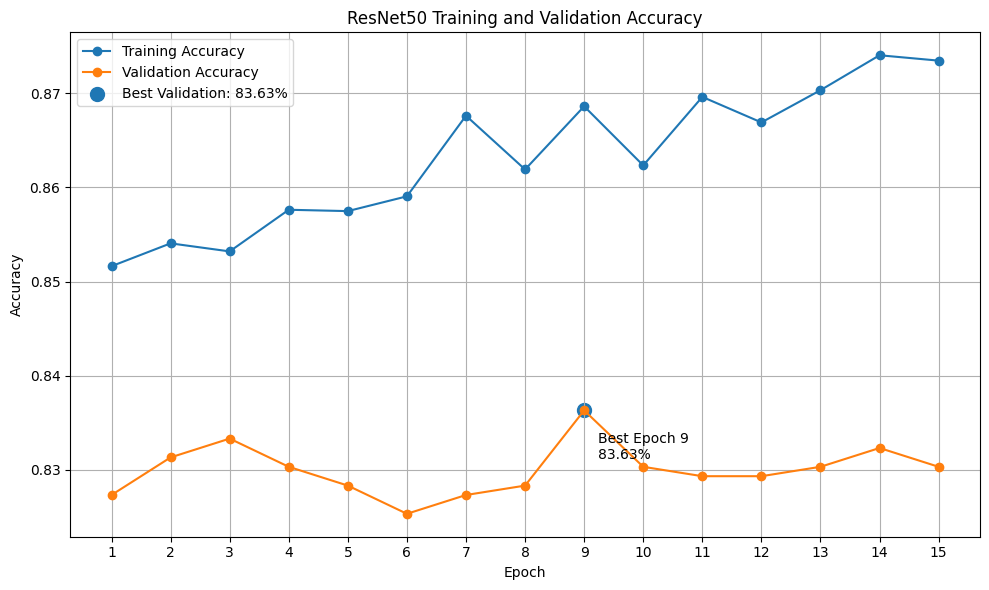

In [99]:
# ============================================
# Experiment 4 - Training Graphs
# ============================================

import matplotlib.pyplot as plt
import numpy as np

history = exp4_history.history

epochs = np.arange(1, len(history["accuracy"]) + 1)

# Find best validation epoch
best_epoch = np.argmax(history["val_accuracy"]) + 1
best_val_accuracy = max(history["val_accuracy"])

print("Total epochs trained:", len(epochs))
print("Best epoch:", best_epoch)
print(f"Best validation accuracy: {best_val_accuracy:.2%}")


# ============================================
# Accuracy Graph
# ============================================

plt.figure(figsize=(10, 6))

plt.plot(
    epochs,
    history["accuracy"],
    marker="o",
    label="Training Accuracy"
)

plt.plot(
    epochs,
    history["val_accuracy"],
    marker="o",
    label="Validation Accuracy"
)

plt.scatter(
    best_epoch,
    best_val_accuracy,
    s=100,
    label=f"Best Validation: {best_val_accuracy:.2%}"
)

plt.annotate(
    f"Best Epoch {best_epoch}\n{best_val_accuracy:.2%}",
    (best_epoch, best_val_accuracy),
    xytext=(10, -35),
    textcoords="offset points"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("ResNet50 Training and Validation Accuracy")
plt.xticks(epochs)
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

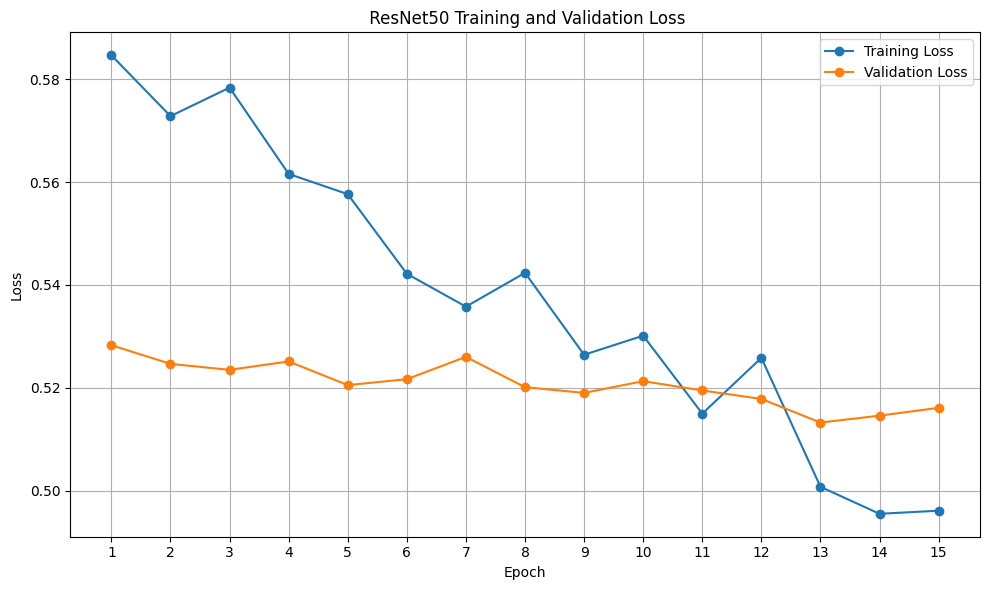

In [100]:
# ============================================
# Experiment 4 - Loss Graph
# ============================================

plt.figure(figsize=(10, 6))

plt.plot(
    epochs,
    history["loss"],
    marker="o",
    label="Training Loss"
)

plt.plot(
    epochs,
    history["val_loss"],
    marker="o",
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title(" ResNet50 Training and Validation Loss")
plt.xticks(epochs)
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

RESNET50 - TRAINING PERFORMANCE
Total Epochs Trained       : 15
Best Epoch                 : 9
Training Accuracy          : 86.8616%
Validation Accuracy        : 83.6327%
Training Loss              : 0.5264
Validation Loss            : 0.5190

RESNET50 - TEST PERFORMANCE
Test Loss                  : 0.5290
Test Accuracy              : 83.0754%

Generating predictions...
63/63 ━━━━━━━━━━━━━━━━━━━━ 8s 121ms/step

Classes:
['akiec' 'bcc' 'bkl' 'df' 'mel' 'nv' 'vasc']

RESNET50 - CLASSIFICATION REPORT
              precision    recall  f1-score   support

       akiec     0.6667    0.4923    0.5664        65
         bcc     0.6939    0.6602    0.6766       103
         bkl     0.6101    0.7682    0.6801       220
          df     0.6471    0.4783    0.5500        23
         mel     0.6226    0.5919    0.6069       223
          nv     0.9268    0.9165    0.9216      1341
        vasc     0.9200    0.8214    0.8679        28

    accuracy                         0.8308      2003
   macro 

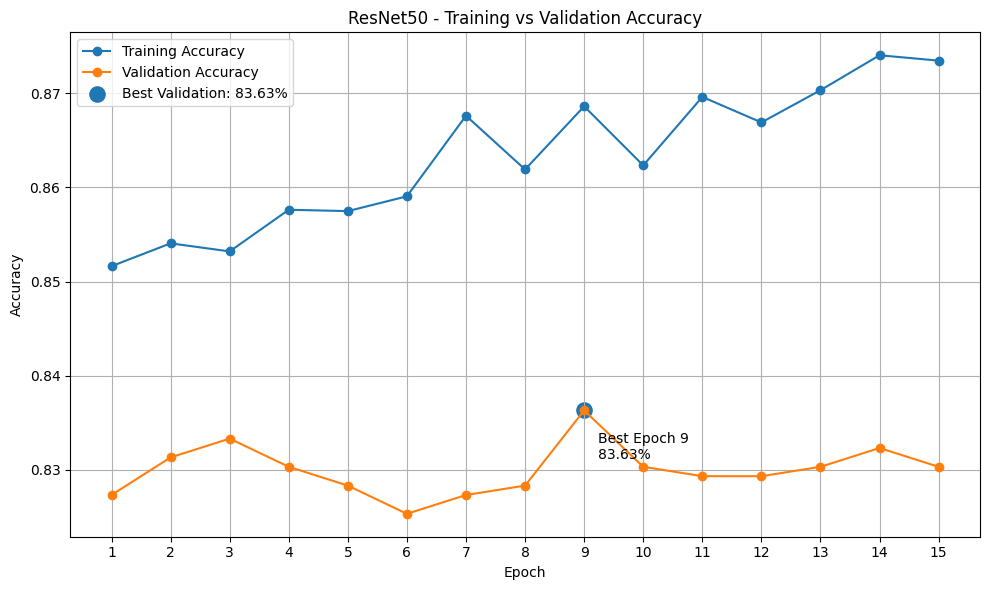

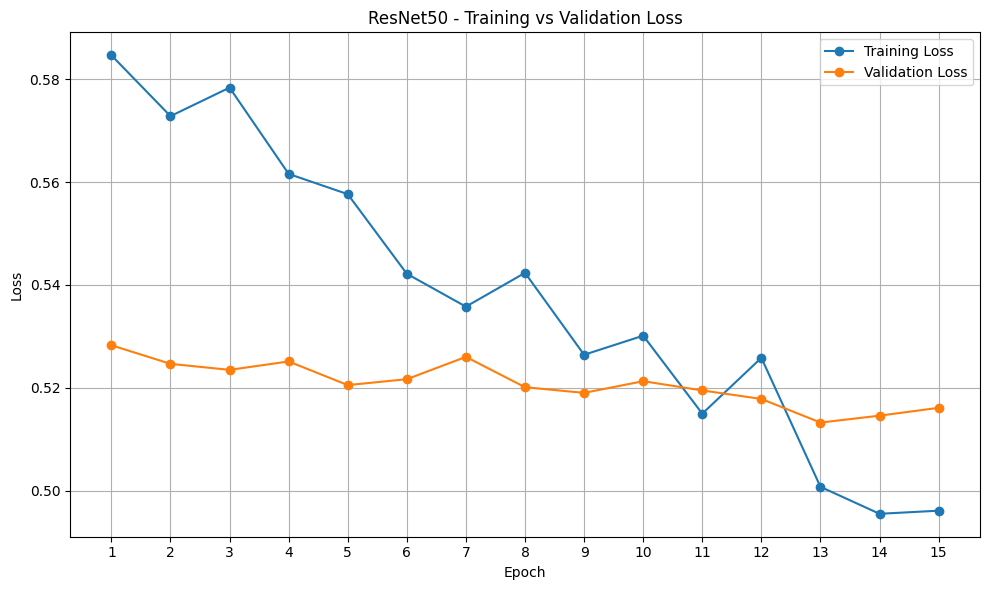

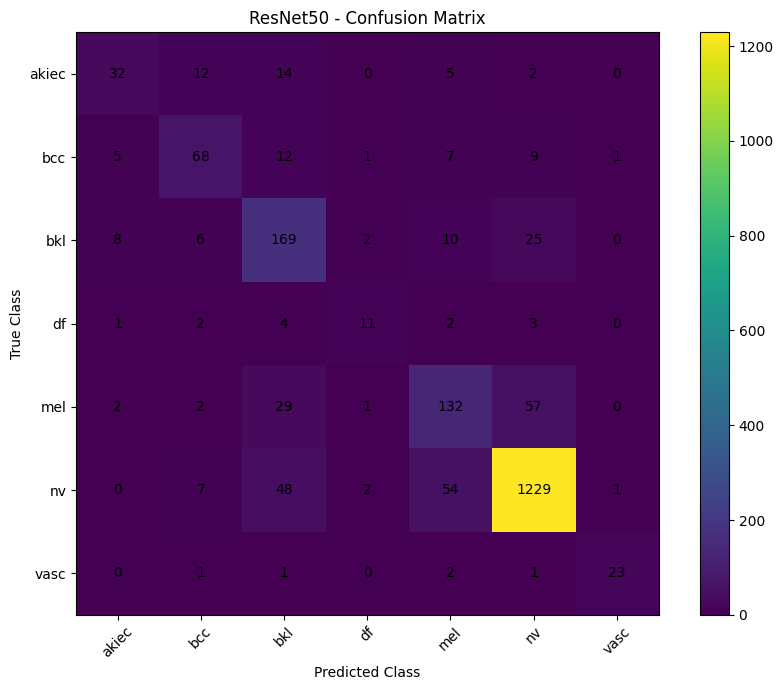


RESNET50 - FILES SAVED
Classification report:
/kaggle/working/resnet50_classification_report.csv

Summary:
/kaggle/working/resnet50_summary.csv


In [103]:
# ============================================================
# RESNET50 - COMPLETE PERFORMANCE REPORT
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    classification_report,
    confusion_matrix
)


# ============================================================
# 1. TRAINING HISTORY
# ============================================================

history = exp4_history.history

epochs = np.arange(
    1,
    len(history["accuracy"]) + 1
)

# Best validation epoch
best_epoch = np.argmax(
    history["val_accuracy"]
) + 1

best_train_accuracy = (
    history["accuracy"][best_epoch - 1]
)

best_val_accuracy = (
    history["val_accuracy"][best_epoch - 1]
)

best_train_loss = (
    history["loss"][best_epoch - 1]
)

best_val_loss = (
    history["val_loss"][best_epoch - 1]
)


# ============================================================
# 2. TRAINING PERFORMANCE
# ============================================================

print("=" * 70)
print("RESNET50 - TRAINING PERFORMANCE")
print("=" * 70)

print(
    f"Total Epochs Trained       : {len(epochs)}"
)

print(
    f"Best Epoch                 : {best_epoch}"
)

print(
    f"Training Accuracy          : "
    f"{best_train_accuracy:.4%}"
)

print(
    f"Validation Accuracy        : "
    f"{best_val_accuracy:.4%}"
)

print(
    f"Training Loss              : "
    f"{best_train_loss:.4f}"
)

print(
    f"Validation Loss            : "
    f"{best_val_loss:.4f}"
)


# ============================================================
# 3. TEST SET EVALUATION
# ============================================================

test_loss, test_accuracy = exp4_model.evaluate(
    test_ds,
    verbose=0
)

print("\n" + "=" * 70)
print("RESNET50 - TEST PERFORMANCE")
print("=" * 70)

print(
    f"Test Loss                  : "
    f"{test_loss:.4f}"
)

print(
    f"Test Accuracy              : "
    f"{test_accuracy:.4%}"
)


# ============================================================
# 4. GENERATE TEST PREDICTIONS
# ============================================================

print("\nGenerating predictions...")

test_predictions = exp4_model.predict(
    test_ds,
    verbose=1
)

test_pred_labels = np.argmax(
    test_predictions,
    axis=1
)

true_labels = np.concatenate([
    y.numpy()
    for _, y in test_ds
])


# ============================================================
# 5. CLASS NAMES
# ============================================================

class_names = label_encoder.classes_

print("\nClasses:")
print(class_names)


# ============================================================
# 6. CLASSIFICATION REPORT
# ============================================================

report_dict = classification_report(
    true_labels,
    test_pred_labels,
    target_names=class_names,
    digits=4,
    output_dict=True
)

print("\n" + "=" * 70)
print("RESNET50 - CLASSIFICATION REPORT")
print("=" * 70)

print(
    classification_report(
        true_labels,
        test_pred_labels,
        target_names=class_names,
        digits=4
    )
)


# ============================================================
# 7. CONFUSION MATRIX
# ============================================================

cm = confusion_matrix(
    true_labels,
    test_pred_labels
)

print("\n" + "=" * 70)
print("RESNET50 - CONFUSION MATRIX")
print("=" * 70)

print(cm)


# ============================================================
# 8. PER-CLASS PERFORMANCE
# ============================================================

class_accuracy = (
    cm.diagonal() /
    cm.sum(axis=1)
)

per_class_df = pd.DataFrame({

    "Class": class_names,

    "Accuracy": class_accuracy,

    "Precision": [
        report_dict[c]["precision"]
        for c in class_names
    ],

    "Recall": [
        report_dict[c]["recall"]
        for c in class_names
    ],

    "F1-Score": [
        report_dict[c]["f1-score"]
        for c in class_names
    ],

    "Support": [
        int(report_dict[c]["support"])
        for c in class_names
    ]
})


print("\n" + "=" * 70)
print("RESNET50 - PER-CLASS PERFORMANCE")
print("=" * 70)

print(
    per_class_df.to_string(
        index=False,
        formatters={
            "Accuracy": "{:.4%}".format,
            "Precision": "{:.4f}".format,
            "Recall": "{:.4f}".format,
            "F1-Score": "{:.4f}".format
        }
    )
)


# ============================================================
# 9. FINAL SUMMARY
# ============================================================

summary_df = pd.DataFrame({

    "Metric": [

        "Best Epoch",

        "Training Accuracy",

        "Validation Accuracy",

        "Training Loss",

        "Validation Loss",

        "Test Accuracy",

        "Test Loss",

        "Macro Precision",

        "Macro Recall",

        "Macro F1-Score",

        "Weighted Precision",

        "Weighted Recall",

        "Weighted F1-Score"
    ],

    "Value": [

        best_epoch,

        f"{best_train_accuracy:.4%}",

        f"{best_val_accuracy:.4%}",

        f"{best_train_loss:.4f}",

        f"{best_val_loss:.4f}",

        f"{test_accuracy:.4%}",

        f"{test_loss:.4f}",

        f"{report_dict['macro avg']['precision']:.4f}",

        f"{report_dict['macro avg']['recall']:.4f}",

        f"{report_dict['macro avg']['f1-score']:.4f}",

        f"{report_dict['weighted avg']['precision']:.4f}",

        f"{report_dict['weighted avg']['recall']:.4f}",

        f"{report_dict['weighted avg']['f1-score']:.4f}"
    ]
})


print("\n" + "=" * 70)
print("RESNET50 - FINAL SUMMARY")
print("=" * 70)

print(
    summary_df.to_string(
        index=False
    )
)


# ============================================================
# 10. ACCURACY GRAPH
# ============================================================

plt.figure(figsize=(10, 6))

plt.plot(
    epochs,
    history["accuracy"],
    marker="o",
    label="Training Accuracy"
)

plt.plot(
    epochs,
    history["val_accuracy"],
    marker="o",
    label="Validation Accuracy"
)

plt.scatter(
    best_epoch,
    best_val_accuracy,
    s=120,
    label=(
        f"Best Validation: "
        f"{best_val_accuracy:.2%}"
    )
)

plt.annotate(
    (
        f"Best Epoch {best_epoch}\n"
        f"{best_val_accuracy:.2%}"
    ),
    (
        best_epoch,
        best_val_accuracy
    ),
    xytext=(10, -35),
    textcoords="offset points"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")

plt.title(
    "ResNet50 - Training vs Validation Accuracy"
)

plt.xticks(epochs)

plt.legend()

plt.grid(True)

plt.tight_layout()

plt.show()


# ============================================================
# 11. LOSS GRAPH
# ============================================================

plt.figure(figsize=(10, 6))

plt.plot(
    epochs,
    history["loss"],
    marker="o",
    label="Training Loss"
)

plt.plot(
    epochs,
    history["val_loss"],
    marker="o",
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")

plt.title(
    "ResNet50 - Training vs Validation Loss"
)

plt.xticks(epochs)

plt.legend()

plt.grid(True)

plt.tight_layout()

plt.show()


# ============================================================
# 12. CONFUSION MATRIX GRAPH
# ============================================================

plt.figure(figsize=(9, 7))

plt.imshow(cm)

plt.title(
    "ResNet50 - Confusion Matrix"
)

plt.xlabel(
    "Predicted Class"
)

plt.ylabel(
    "True Class"
)

plt.xticks(
    range(len(class_names)),
    class_names,
    rotation=45
)

plt.yticks(
    range(len(class_names)),
    class_names
)

plt.colorbar()

for i in range(len(class_names)):

    for j in range(len(class_names)):

        plt.text(
            j,
            i,
            cm[i, j],
            ha="center",
            va="center"
        )

plt.tight_layout()

plt.show()


# ============================================================
# 13. SAVE RESULTS TO CSV
# ============================================================

per_class_df.to_csv(
    "/kaggle/working/resnet50_classification_report.csv",
    index=False
)

summary_df.to_csv(
    "/kaggle/working/resnet50_summary.csv",
    index=False
)

print("\n" + "=" * 70)
print("RESNET50 - FILES SAVED")
print("=" * 70)

print(
    "Classification report:"
)

print(
    "/kaggle/working/"
    "resnet50_classification_report.csv"
)

print(
    "\nSummary:"
)

print(
    "/kaggle/working/"
    "resnet50_summary.csv"
)

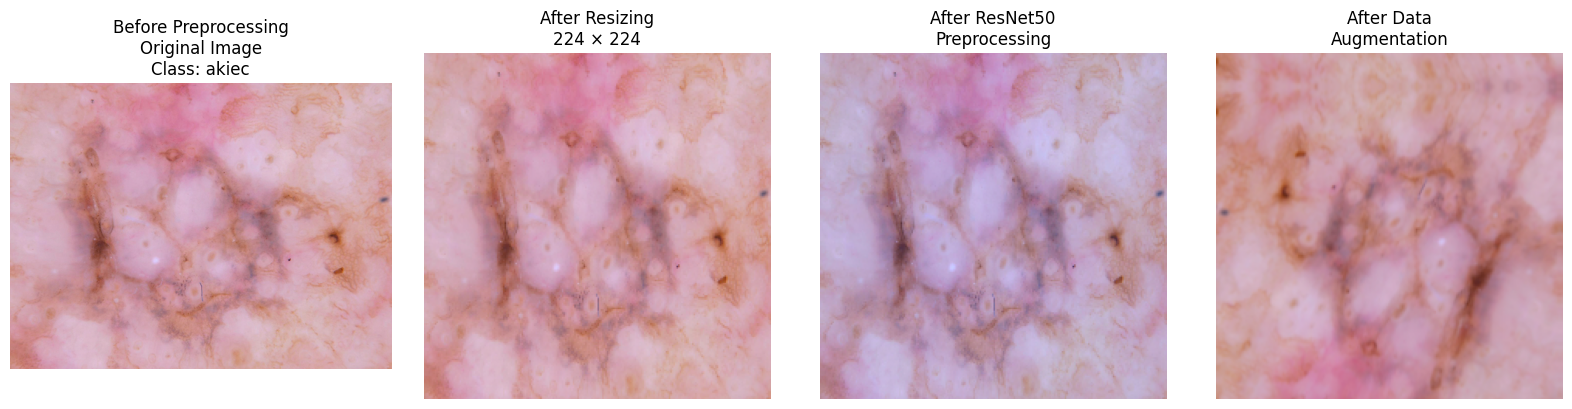

RESNET50 - IMAGE PREPROCESSING INFORMATION
Original image shape       : (450, 600, 3)
Resized image shape        : (224, 224, 3)
Preprocessed image shape   : (224, 224, 3)
Augmented image shape      : (224, 224, 3)

Original pixel range       : 11.0 to 255.0
Resized pixel range        : 24.492279052734375 to 250.09620666503906
Preprocessed pixel range   : -79.44672393798828 to 146.15719604492188
Augmented pixel range     : 21.111560821533203 to 237.9681854248047


In [104]:
# ============================================================
# RESNET50 - BEFORE AND AFTER PREPROCESSING VISUALIZATION
# ============================================================

import matplotlib.pyplot as plt
import tensorflow as tf
import numpy as np

# ------------------------------------------------------------
# Select one image from the training dataset
# ------------------------------------------------------------

sample_path = train_paths[0]
sample_label = train_labels[0]

# ------------------------------------------------------------
# 1. Load ORIGINAL image
# ------------------------------------------------------------

original_image = tf.io.read_file(sample_path)

original_image = tf.image.decode_jpeg(
    original_image,
    channels=3
)

# Keep original for visualization
original_image_display = original_image.numpy()

# ------------------------------------------------------------
# 2. Resize image to 224 x 224
# ------------------------------------------------------------

resized_image = tf.image.resize(
    original_image,
    (224, 224)
)

resized_image = tf.cast(
    resized_image,
    tf.float32
)

# ------------------------------------------------------------
# 3. ResNet50 preprocessing
# ------------------------------------------------------------

preprocessed_image = tf.keras.applications.resnet50.preprocess_input(
    resized_image
)

# ------------------------------------------------------------
# 4. Apply augmentation
# ------------------------------------------------------------

augmented_image = paper_augmentation(
    tf.expand_dims(resized_image, axis=0),
    training=True
)[0]

# ------------------------------------------------------------
# 5. Display images
# ------------------------------------------------------------

plt.figure(figsize=(16, 4))

# Original
plt.subplot(1, 4, 1)

plt.imshow(
    original_image_display.astype("uint8")
)

plt.title(
    f"Before Preprocessing\n"
    f"Original Image\n"
    f"Class: {class_names[sample_label]}"
)

plt.axis("off")


# Resized
plt.subplot(1, 4, 2)

plt.imshow(
    resized_image.numpy().astype("uint8")
)

plt.title(
    "After Resizing\n224 × 224"
)

plt.axis("off")


# Preprocessed
plt.subplot(1, 4, 3)

# ResNet50 preprocessing converts RGB values approximately
# to the range expected by the ImageNet-trained network.
# Convert back to displayable RGB for visualization.

display_preprocessed = preprocessed_image.numpy()

# Reverse ResNet50 preprocessing:
# BGR + mean subtraction -> RGB 0-255
display_preprocessed = display_preprocessed[..., ::-1]

display_preprocessed = display_preprocessed + np.array(
    [103.939, 116.779, 123.68]
)

display_preprocessed = np.clip(
    display_preprocessed,
    0,
    255
)

plt.imshow(
    display_preprocessed.astype("uint8")
)

plt.title(
    "After ResNet50\nPreprocessing"
)

plt.axis("off")


# Augmented
plt.subplot(1, 4, 4)

plt.imshow(
    tf.clip_by_value(
        augmented_image,
        0,
        255
    ).numpy().astype("uint8")
)

plt.title(
    "After Data\nAugmentation"
)

plt.axis("off")


plt.tight_layout()

plt.show()


# ============================================================
# PRINT IMAGE INFORMATION
# ============================================================

print("=" * 60)
print("RESNET50 - IMAGE PREPROCESSING INFORMATION")
print("=" * 60)

print(
    "Original image shape       :",
    original_image.shape
)

print(
    "Resized image shape        :",
    resized_image.shape
)

print(
    "Preprocessed image shape   :",
    preprocessed_image.shape
)

print(
    "Augmented image shape      :",
    augmented_image.shape
)

print()

print(
    "Original pixel range       :",
    float(tf.reduce_min(original_image)),
    "to",
    float(tf.reduce_max(original_image))
)

print(
    "Resized pixel range        :",
    float(tf.reduce_min(resized_image)),
    "to",
    float(tf.reduce_max(resized_image))
)

print(
    "Preprocessed pixel range   :",
    float(tf.reduce_min(preprocessed_image)),
    "to",
    float(tf.reduce_max(preprocessed_image))
)

print(
    "Augmented pixel range     :",
    float(tf.reduce_min(augmented_image)),
    "to",
    float(tf.reduce_max(augmented_image))
)